In [1]:
rm(list = ls())
options(stringsAsFactors = FALSE)
getwd()

[1] "/Users/luye/Library/Mobile Documents/com~apple~CloudDocs/Projects/Ongoing/202504ZL"

In [2]:
sample_cluster <- readxl::read_excel("./1-Clustering/data/sample_info_with_clusters.xlsx")
dim(sample_cluster)
head(sample_cluster)

[1] 586  38

Sample,NMF,KMeans,Ensemble,Study,Platform,Sex,Age_num,Age_group,Country,...,Distal metastasis (1=Positive),"TB, total bilirubin (µmol/L)","ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling
<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
111,3,1,C2_C3,2022Dong,RNAseq (Illumina),Male,49,40-60,China,...,0,8.4,36,5147,2.5,25.2,18,80,YES,NO
113,2,1,C2,2022Dong,RNAseq (Illumina),Male,59,40-60,China,...,0,9.1999999999999993,38,1.8,2.8,35,18,40,YES,NO
115,1,3,C1,2022Dong,RNAseq (Illumina),Male,74,>60,China,...,0,7.9,39,42.7,2,8.1999999999999904,11,29,YES,YES
117,1,3,C1,2022Dong,RNAseq (Illumina),Female,64,>60,China,...,0,14.1,47,2.8,1,7.9,17,27,YES,YES
121,2,1,C2,2022Dong,RNAseq (Illumina),Female,71,>60,China,...,0,8.6,42,215.1,1.4,24.9,10,23,YES,YES
123,1,3,C1,2022Dong,RNAseq (Illumina),Male,55,40-60,China,...,0,17.8,44,2.1,0.8,30.4,89,384,YES,YES


# **SNV**

In [18]:
library(tidyverse)
library(maftools)
library(dplyr)
library(ggplot2)
library(ggpubr)

In [9]:
snv <- read.csv("./0-Data/combined_maf_data.csv")
dim(snv)
head(snv)

[1] 20893    10

,Hugo_Symbol,Chromosome,Start_Position,End_Position,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,Tumor_Sample_Barcode,Dataset
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,EPHA2,chr1,16135156,16135156,Nonsense_Mutation,SNP,C,A,TCGA-W6-AA0T,TCGA
2,HMCN1,chr1,186045803,186045803,Silent,SNP,C,T,TCGA-W6-AA0T,TCGA
3,ELF3,chr1,202013256,202013257,Frame_Shift_Del,DEL,AA,-,TCGA-W6-AA0T,TCGA
4,NID1,chr1,236045570,236045570,Missense_Mutation,SNP,G,T,TCGA-W6-AA0T,TCGA
5,CAD,chr2,27238158,27238166,In_Frame_Del,DEL,CACATATGT,-,TCGA-W6-AA0T,TCGA
6,PCARE,chr2,29072933,29072933,Silent,SNP,G,A,TCGA-W6-AA0T,TCGA


In [8]:
samples <- sample_cluster$Sample
length(samples)

[1] 586

In [ ]:
snv_df <- snv[snv$Tumor_Sample_Barcode %in% samples,]
dim(snv_df)
head(snv_df)

In [19]:
maf_input <- snv_df %>% select(-Dataset) # 移除临床信息

In [20]:
clinical_input <- snv_df %>%
  select(Tumor_Sample_Barcode, Dataset) %>%
  left_join(sample_cluster %>% select(Sample, Ensemble), 
            by = c("Tumor_Sample_Barcode" = "Sample")) %>%
  distinct()
dim(clinical_input)
head(clinical_input)

[1] 312   3

,Tumor_Sample_Barcode,Dataset,Ensemble
,<chr>,<chr>,<chr>
1,CCA#32,Deng2023,C2
2,CCA#36,Deng2023,C1
3,CCA#38,Deng2023,C1_C2
4,CCA#46,Deng2023,C2
5,CCA#47,Deng2023,C2
6,CCA#50,Deng2023,C3


In [21]:
# 创建maftools对象
maf_obj <- read.maf(
  maf = maf_input,
  clinicalData = clinical_input,
  verbose = FALSE
)

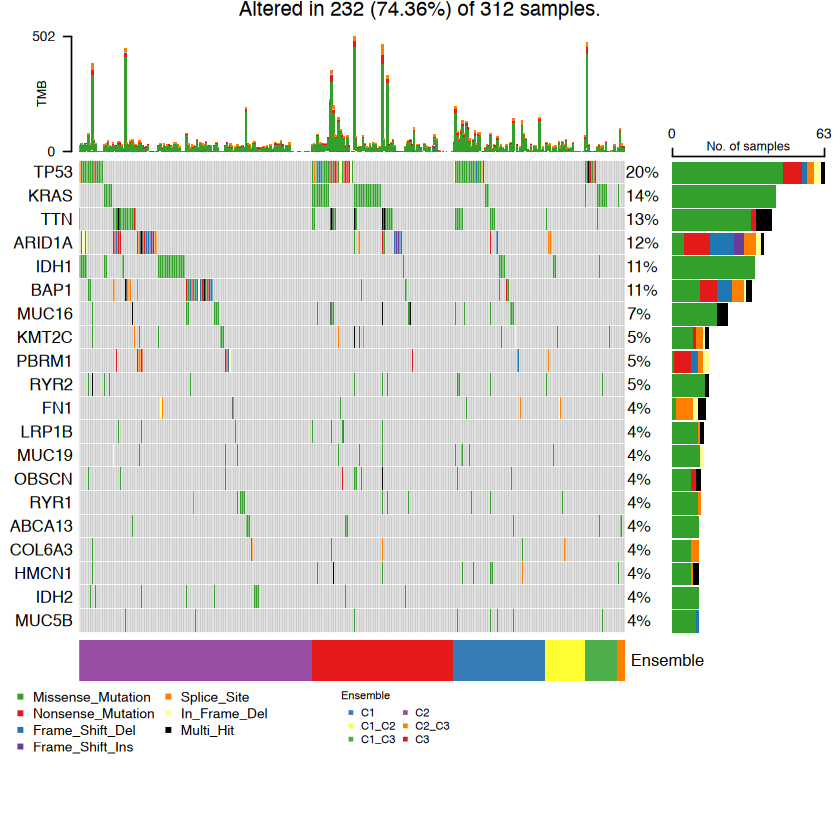

In [27]:
# 绘制Oncoplot，按亚型注释和排序，并强制显示您关心的driver gene
oncoplot(
  maf = maf_obj,
  clinicalFeatures = 'Ensemble', # 按亚型给样本条上色
  sortByAnnotation = TRUE, # 按亚型对样本进行排序
  showTumorSampleBarcodes = FALSE,
  removeNonMutated = FALSE, # 设置为FALSE以显示完整队列
  annotationFontSize = 0.8,
  legendFontSize = 1.0
)

In [22]:
drivers <- c("TP53","KRAS","BAP1","IDH1","ARID1A","PBRM1","IDH2","FGFR2","SMAD4","STK11","APC","TERT",
               "KMT2C","DPCR1","MGA","KTM2A","KTM2D","ATM","NCOR1","EPHA2","RML","TET2","NF1","ARID2","MSH6","RBM47")

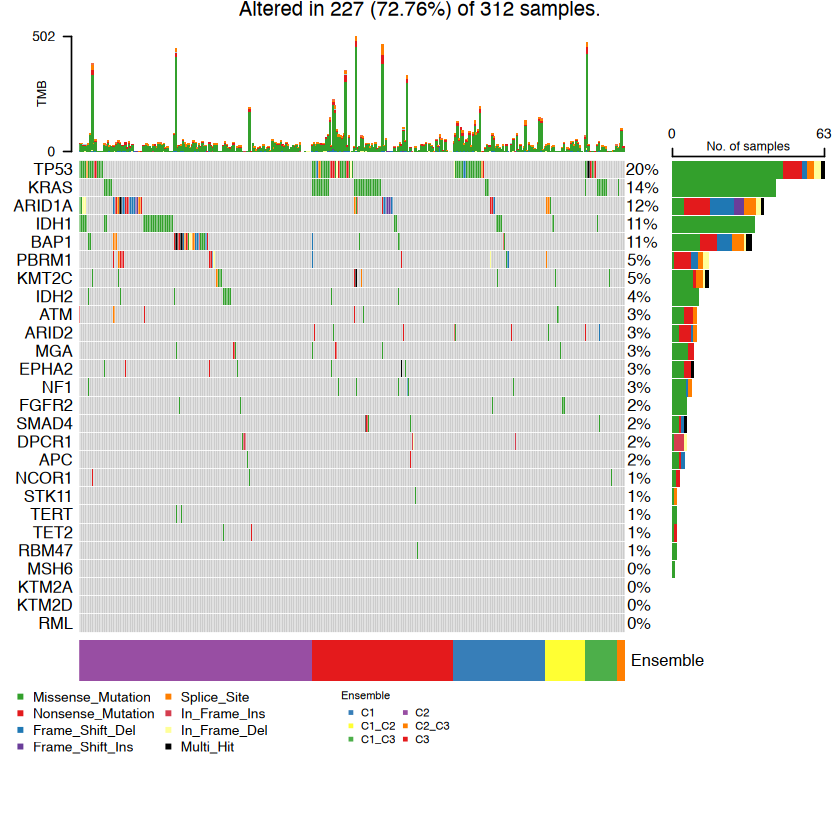

In [24]:
# 绘制Oncoplot，按亚型注释和排序，并强制显示您关心的driver gene
oncoplot(
  maf = maf_obj,
  genes = drivers, # 强制显示这个列表中的所有基因
  clinicalFeatures = 'Ensemble', # 按亚型给样本条上色
  sortByAnnotation = TRUE, # 按亚型对样本进行排序
  showTumorSampleBarcodes = FALSE,
  removeNonMutated = FALSE, # 设置为FALSE以显示完整队列
  annotationFontSize = 0.8,
  legendFontSize = 1.0
)

-subsetting by clinical data..

--53 samples meet the clinical query



--Possible FLAGS among top ten genes:
  TTN
  MUC16
  HMCN1
-Processing clinical data


-subsetting by clinical data..

--133 samples meet the clinical query



--Possible FLAGS among top ten genes:
  TTN
  MUC16
-Processing clinical data


-subsetting by clinical data..

--81 samples meet the clinical query



--Possible FLAGS among top ten genes:
  TTN
  MUC16
  PLEC
  OBSCN
-Processing clinical data
--- C1 vs C2 <U+4E9A><U+578B><U+7A81><U+53D8><U+5DEE><U+5F02><U+7ED3><U+679C> ---
    Hugo_Symbol Subtype_C1 Subtype_C2         pval         or       ci.up
         <char>      <num>      <num>        <num>      <num>       <num>
 1:        TP53         18         14 0.0004246865  4.2208752  10.2137333
 2:       ALMS1          5          0 0.0017729190        Inf         Inf
 3:       HMCN1          5          1 0.0082470612 13.2286689 638.0459088
 4:        BAP1          3         26 0.0145919836  0.2414601   0.8454389
 5:        IDH2          0          9 0.0609195933  0.0000000   1.2092658
 6:        IDH1          4         25 0.0722895473  0.3445412   1.0758249
 7:      ARID1A          3         21 0.0884232795  0.3130315   1.1214008
 8:       MUC16          6          7 0.2031879181  2.2320611   8.2124926
 9:         FN1          4          5 0.2850517483  2.0320135   9.8784249
10:        

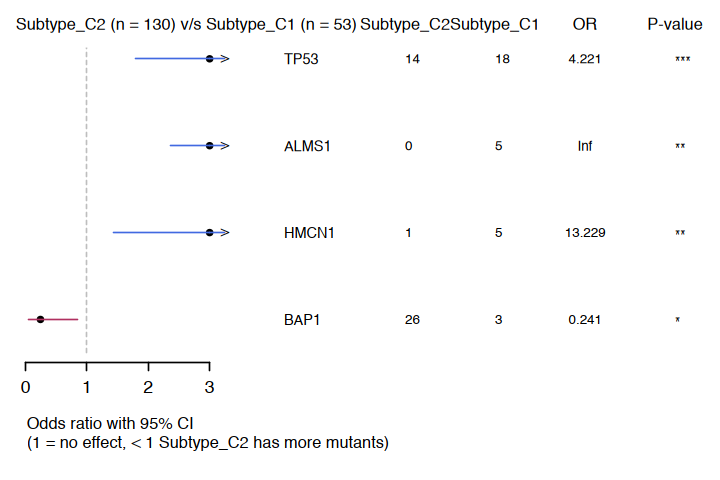


--- C2 vs C3 <U+4E9A><U+578B><U+7A81><U+53D8><U+5DEE><U+5F02><U+7ED3><U+679C> ---
    Hugo_Symbol Subtype_C2 Subtype_C3         pval         or       ci.up
         <char>      <num>      <num>        <num>      <num>       <num>
 1:        KRAS          5         26 1.636141e-08 0.08261131   0.2341778
 2:        IDH1         25          2 2.356044e-04 9.09794321  81.5799479
 3:        TP53         14         24 7.021632e-04 0.27844388   0.6098327
 4:        BAP1         26          4 2.230156e-03 4.65895748  19.1299487
 5:     CCDC168          0          6 2.581593e-03 0.00000000   0.4951868
 6:      STARD9          0          6 2.581593e-03 0.00000000   0.4951868
 7:     CNTNAP5          0          5 7.116824e-03 0.00000000   0.6433682
 8:       SMAD4          0          5 7.116824e-03 0.00000000   0.6433682
 9:        PLEC          1          6 1.250101e-02 0.09532277   0.8086866
10:         DMD          2          5 1.068544e-01 0.23292221   1.4657465
11:         NF1          2   

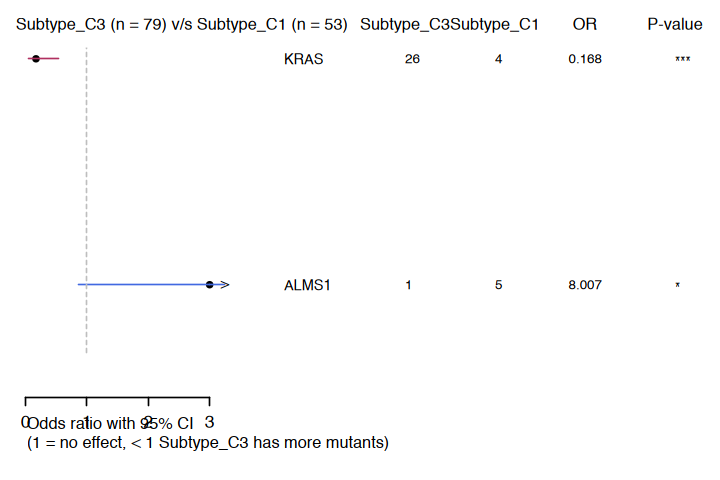

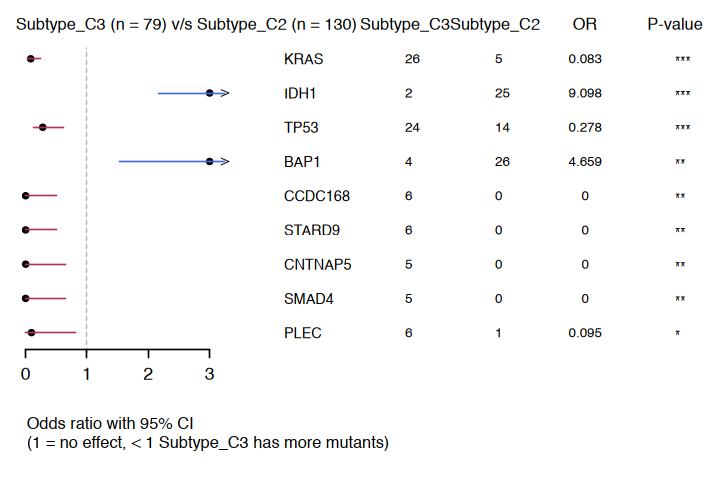

In [35]:
library(maftools)
options(repr.plot.height = 4, repr.plot.width =6)
# 假设 maf_obj 是您已经创建好的、包含所有样本和亚型信息的maftools对象

# 1. 为每个亚型创建一个独立的maf子集
maf_C1 <- subsetMaf(maf = maf_obj, clinQuery = "Ensemble == 'C1'")
maf_C2 <- subsetMaf(maf = maf_obj, clinQuery = "Ensemble == 'C2'")
maf_C3 <- subsetMaf(maf = maf_obj, clinQuery = "Ensemble == 'C3'")

# 2. 进行第一次两两比较：C1 vs C2
comp_C1_vs_C2 <- mafCompare(
  m1 = maf_C1,
  m2 = maf_C2,
  m1Name = 'Subtype_C1',
  m2Name = 'Subtype_C2',
  minMut = 5 # 至少在一个亚型中有5个突变才进行比较
)

cat("--- C1 vs C2 亚型突变差异结果 ---\n")
print(comp_C1_vs_C2$results)

# 可视化比较结果
forestPlot(mafCompareRes = comp_C1_vs_C2, pVal = 0.05,geneFontSize = 0.7)


# 3. 进行第二次两两比较：C1 vs C3
comp_C1_vs_C3 <- mafCompare(
  m1 = maf_C1,
  m2 = maf_C3,
  m1Name = 'Subtype_C1',
  m2Name = 'Subtype_C3',
  minMut = 5
)
cat("\n--- C1 vs C3 亚型突变差异结果 ---\n")
print(comp_C1_vs_C3$results)
forestPlot(mafCompareRes = comp_C1_vs_C3, pVal = 0.05,geneFontSize = 0.7)


# 4. 进行第三次两两比较：C2 vs C3
comp_C2_vs_C3 <- mafCompare(
  m1 = maf_C2,
  m2 = maf_C3,
  m1Name = 'Subtype_C2',
  m2Name = 'Subtype_C3',
  minMut = 5
)
cat("\n--- C2 vs C3 亚型突变差异结果 ---\n")
print(comp_C2_vs_C3$results)
forestPlot(mafCompareRes = comp_C2_vs_C3, pVal = 0.05,geneFontSize = 0.7)


-subsetting by clinical data..

--53 samples meet the clinical query



--Possible FLAGS among top ten genes:
  TTN
  MUC16
  HMCN1
-Processing clinical data


-subsetting by clinical data..

--259 samples meet the clinical query



--Possible FLAGS among top ten genes:
  TTN
  MUC16
-Processing clinical data
--- C1 vs Others <U+4E9A><U+578B><U+7A81><U+53D8><U+5DEE><U+5F02><U+7ED3><U+679C> ---
     Hugo_Symbol Subtype_C1 Others        pval         or      ci.up     ci.low
          <char>      <num>  <int>       <num>      <num>      <num>      <num>
  1:       ALMS1          5      2 0.002094814 12.9007318 139.407704 2.04097554
  2:        TP53         18     45 0.014021772  2.3691264   4.756488 1.15544331
  3:       HMCN1          5      6 0.026158644  4.2591810  17.516405 0.98640536
  4:       ZFHX4          4      5 0.051691400  4.0228479  19.429134 0.76989595
  5:       DNAH5          4      6 0.075199007  3.3423834  14.706980 0.66836156
 ---                                                                           
124:        FLNC          1      7 1.000000000  0.6765914   5.450032 0.01471966
125:         NF1          1      7 1.000000000  0.6765914   5.450032 0.01471966
126:       OBSCN          2     10 1

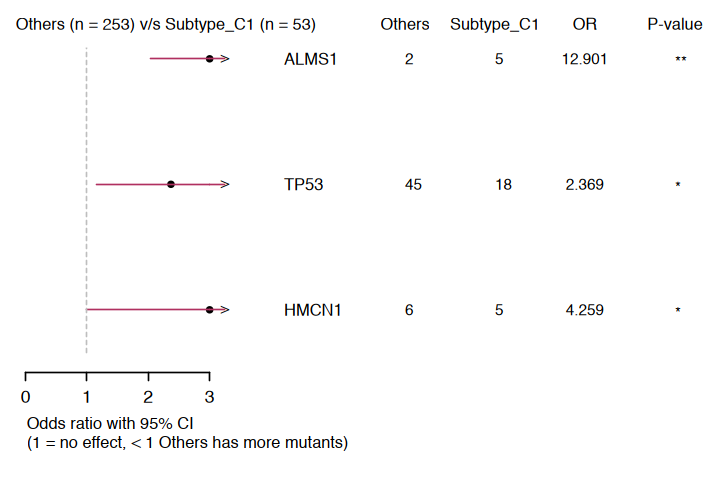

In [42]:
# 比较C1和C2亚型的突变谱差异
# 您可以修改 m1Name 和 m2Name 来比较任意两个亚型
options(repr.plot.height = 4, repr.plot.width =6)
subtype_comp <- mafCompare(
  m1 = subsetMaf(maf = maf_obj, clinQuery = "Ensemble == 'C1'"),
  m2 = subsetMaf(maf = maf_obj, clinQuery = "Ensemble != 'C1'"),
  m1Name = 'Subtype_C1',
  m2Name = 'Others',
  minMut = 5 # 至少在一个亚型中有5个突变才进行比较
)

cat("--- C1 vs Others 亚型突变差异结果 ---\n")
print(subtype_comp$results)

# 可视化这个比较结果
forestPlot(
  mafCompareRes = subtype_comp,
  pVal = 0.05, # p值阈值，小于0.1的会被标记
  color = c('royalblue', 'maroon'),
  geneFontSize = 0.8
)

-subsetting by clinical data..

--133 samples meet the clinical query



--Possible FLAGS among top ten genes:
  TTN
  MUC16
-Processing clinical data


-subsetting by clinical data..

--179 samples meet the clinical query



--Possible FLAGS among top ten genes:
  TTN
  MUC16
  HMCN1
-Processing clinical data
--- C2 vs Others <U+4E9A><U+578B><U+7A81><U+53D8><U+5DEE><U+5F02><U+7ED3><U+679C> ---
    Hugo_Symbol Subtype_C2 Others         pval        or       ci.up
         <char>      <num>  <num>        <num>     <num>       <num>
 1:        KRAS          5     38 4.130176e-06 0.1460173   0.3877942
 2:        BAP1         26      7 9.543435e-06 6.0006737  16.9717508
 3:        IDH1         25      9 1.579663e-04 4.3963406  11.1360555
 4:        TP53         14     49 3.015656e-04 0.3139252   0.6145249
 5:       ARID2          0     10 5.965169e-03 0.0000000   0.5840106
 6:     CCDC168          0     10 5.965169e-03 0.0000000   0.5840106
 7:        IDH2          9      2 1.043907e-02 6.4357468  62.2795159
 8:        DQX1          5      0 1.323040e-02       Inf         Inf
 9:       ALMS1          0      7 2.204467e-02 0.0000000   0.9224895
10:      STARD9          0      7 2.204467e-02 0.0000000   0.9224895


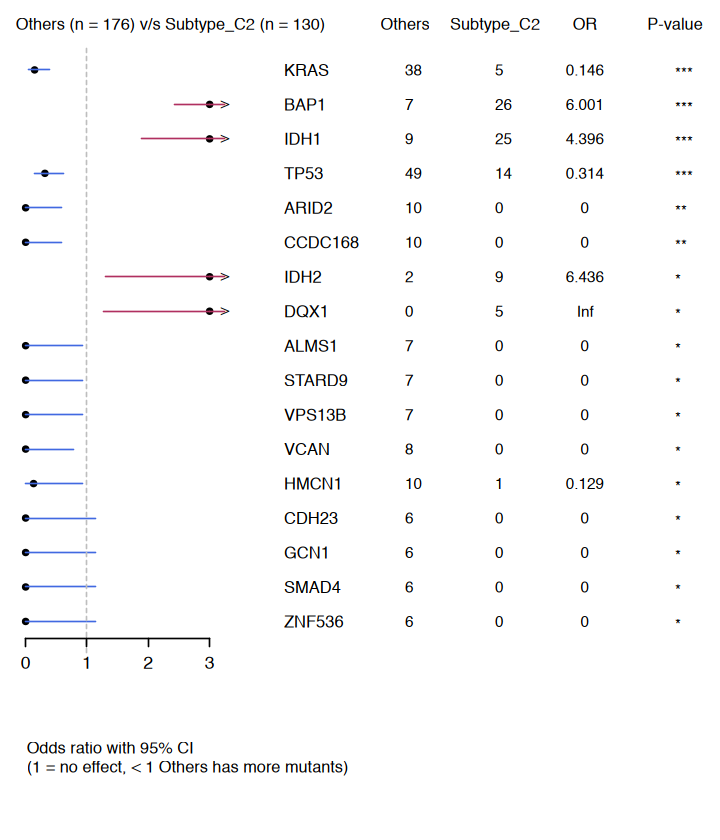

In [44]:
# 比较C1和C2亚型的突变谱差异
# 您可以修改 m1Name 和 m2Name 来比较任意两个亚型
options(repr.plot.height = 7, repr.plot.width =6)
subtype_comp <- mafCompare(
  m1 = subsetMaf(maf = maf_obj, clinQuery = "Ensemble == 'C2'"),
  m2 = subsetMaf(maf = maf_obj, clinQuery = "Ensemble != 'C2'"),
  m1Name = 'Subtype_C2',
  m2Name = 'Others',
  minMut = 5 # 至少在一个亚型中有5个突变才进行比较
)

cat("--- C2 vs Others 亚型突变差异结果 ---\n")
print(subtype_comp$results)

# 可视化这个比较结果
forestPlot(
  mafCompareRes = subtype_comp,
  pVal = 0.05, # p值阈值，小于0.1的会被标记
  color = c('royalblue', 'maroon'),
  geneFontSize = 0.8
)

-subsetting by clinical data..

--81 samples meet the clinical query



--Possible FLAGS among top ten genes:
  TTN
  MUC16
  PLEC
  OBSCN
-Processing clinical data


-subsetting by clinical data..

--231 samples meet the clinical query



--Possible FLAGS among top ten genes:
  TTN
  MUC16
-Processing clinical data
--- C3 vs Others <U+4E9A><U+578B><U+7A81><U+53D8><U+5DEE><U+5F02><U+7ED3><U+679C> ---
    Hugo_Symbol Subtype_C3 Others         pval         or       ci.up
         <char>      <num>  <num>        <num>      <num>       <num>
 1:        KRAS         26     17 1.834042e-07  6.0137017  12.7605725
 2:     CNTNAP5          5      0 1.041700e-03        Inf         Inf
 3:      STARD9          6      1 1.418789e-03 18.3829682 854.0656880
 4:        IDH1          2     32 3.189337e-03  0.1588861   0.6491011
 5:       SMAD4          5      1 4.969707e-03 15.1127441 722.4153522
 6:        PLEC          6      3 1.068771e-02  6.0919471  38.6258485
 7:         DMD          5      2 1.384700e-02  7.5402019  80.5668210
 8:        TP53         24     39 1.552466e-02  2.0978492   3.9351067
 9:     CCDC168          6      4 2.119712e-02  4.5536036  22.5636832
10:         NF1          5      3 2.943423e-02  5.0114842  33.0716

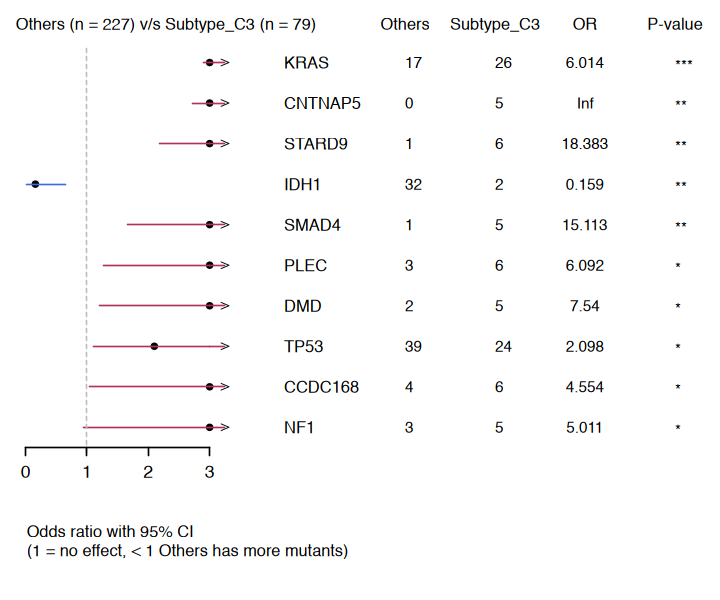

In [43]:
# 比较C1和C2亚型的突变谱差异
# 您可以修改 m1Name 和 m2Name 来比较任意两个亚型
options(repr.plot.height = 5, repr.plot.width =6)
subtype_comp <- mafCompare(
  m1 = subsetMaf(maf = maf_obj, clinQuery = "Ensemble == 'C3'"),
  m2 = subsetMaf(maf = maf_obj, clinQuery = "Ensemble != 'C3'"),
  m1Name = 'Subtype_C3',
  m2Name = 'Others',
  minMut = 5 # 至少在一个亚型中有5个突变才进行比较
)

cat("--- C3 vs Others 亚型突变差异结果 ---\n")
print(subtype_comp$results)

# 可视化这个比较结果
forestPlot(
  mafCompareRes = subtype_comp,
  pVal = 0.05, # p值阈值，小于0.1的会被标记
  color = c('royalblue', 'maroon'),
  geneFontSize = 0.8
)

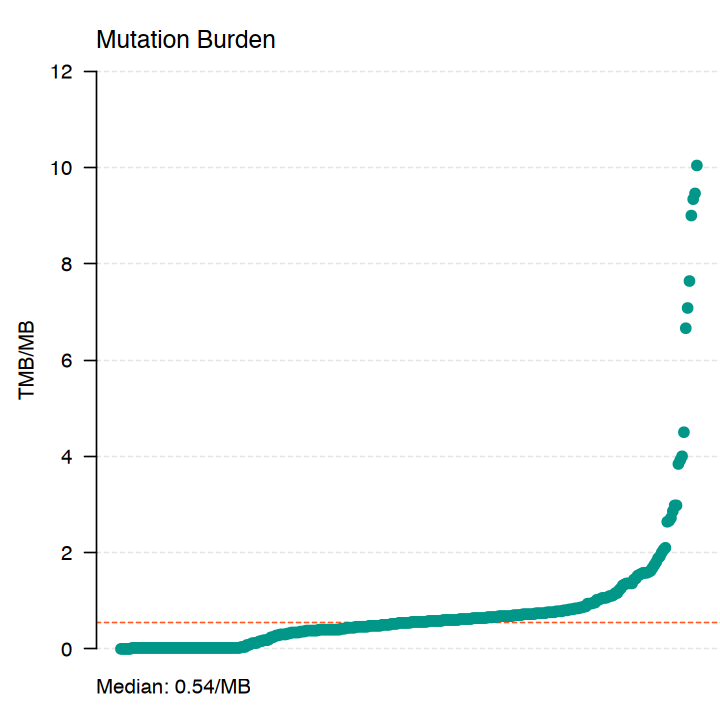

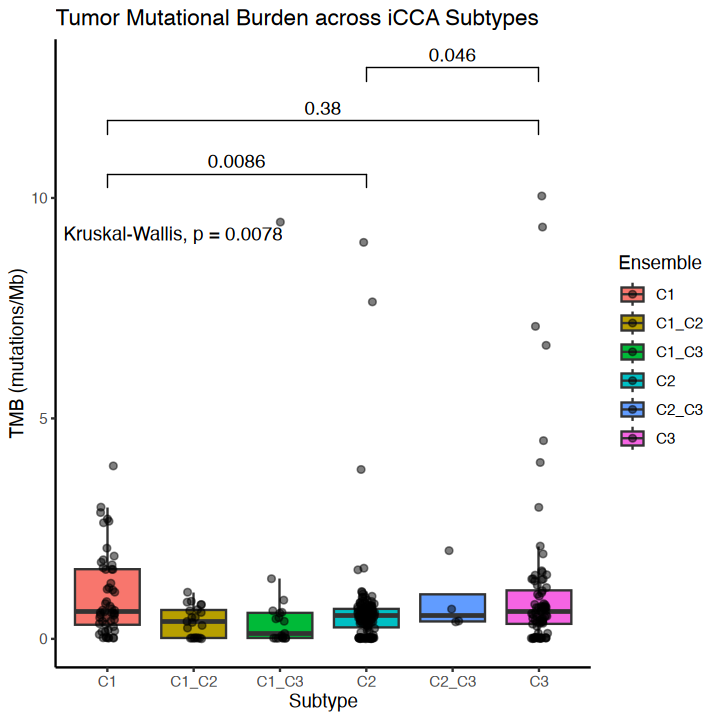

In [55]:
options(repr.plot.height = 6, repr.plot.width =6)
# 1. Calculate TMB and store the results in a new data frame
tmb_results <- tmb(maf = maf_obj, captureSize = 50, logScale = FALSE)

# 2. Get the clinical data from the MAF object
clinical_data <- maf_obj@clinical.data

# 3. Explicitly merge the TMB results with the clinical data
# This creates a new, complete data frame for plotting.
clinical_data_for_plot <- left_join(clinical_data, tmb_results, by = "Tumor_Sample_Barcode")

# 4. Use the new 'clinical_data_for_plot' data frame for visualization
# Note that the y-axis variable is now correctly named 'total_per_mb'
ggplot(clinical_data_for_plot, aes(x = Ensemble, y = total_perMB, fill = Ensemble)) +
  geom_boxplot(outlier.shape = NA) +
  geom_jitter(width = 0.1, alpha = 0.5) +
  stat_compare_means(
    comparisons = list(c("C1", "C2"), c("C1", "C3"), c("C2", "C3")),
    method = "wilcox.test"
  ) +
  stat_compare_means(method = "kruskal.test", label.y.npc = 0.9) +
  labs(
    title = "Tumor Mutational Burden across iCCA Subtypes",
    x = "Subtype",
    y = "TMB (mutations/Mb)"
  ) +
  theme_classic()

Warning message in scale_y_log10():
"log-10 transformation introduced infinite values."
Warning message in scale_y_log10():
"log-10 transformation introduced infinite values."
Warning message in scale_y_log10():
"log-10 transformation introduced infinite values."
Warning message in scale_y_log10():
"log-10 transformation introduced infinite values."
Warning message:
"Removed 6 rows containing non-finite outside the scale range
(`stat_boxplot()`)."
Warning message:
"Removed 6 rows containing non-finite outside the scale range (`stat_signif()`)."
Warning message:
"Removed 6 rows containing non-finite outside the scale range
(`stat_compare_means()`)."


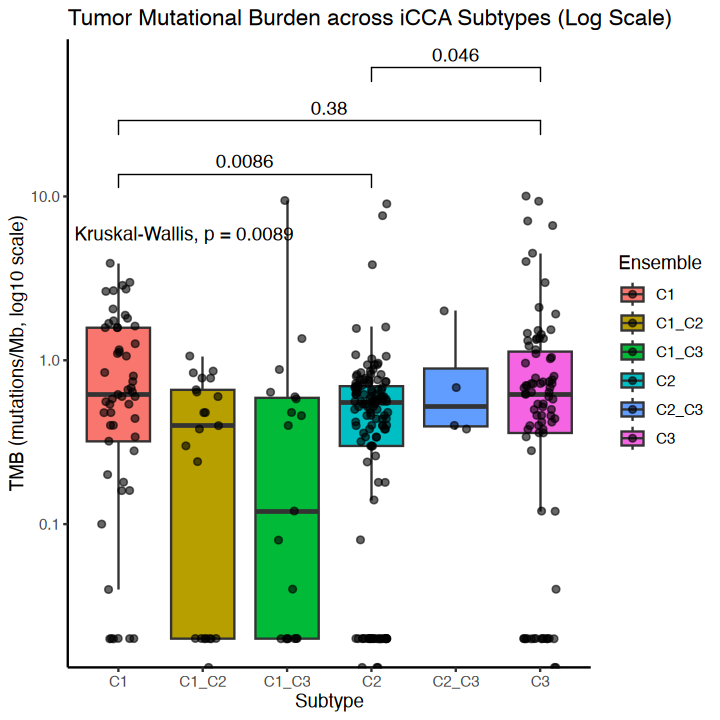

In [54]:
# --- 方案B：如果希望Y轴为对数刻度（推荐的可选方案）---
ggplot(clinical_data_for_plot, aes(x = Ensemble, y = total_perMB, fill = Ensemble)) +
  geom_boxplot(outlier.shape = NA) +
  geom_jitter(width = 0.2, alpha = 0.6) +
  
  # 添加这一行来将Y轴转换为对数刻度
  scale_y_log10() +
  
  # 在对数刻度下，统计检验的P值位置可能需要手动调整
  stat_compare_means(
    comparisons = list(c("C1", "C2"), c("C1", "C3"), c("C2", "C3")),
    method = "wilcox.test"
  ) +
  stat_compare_means(method = "kruskal.test", label.y.npc = 0.9) +
  labs(
    title = "Tumor Mutational Burden across iCCA Subtypes (Log Scale)",
    x = "Subtype",
    y = "TMB (mutations/Mb, log10 scale)"
  ) +
  theme_classic()

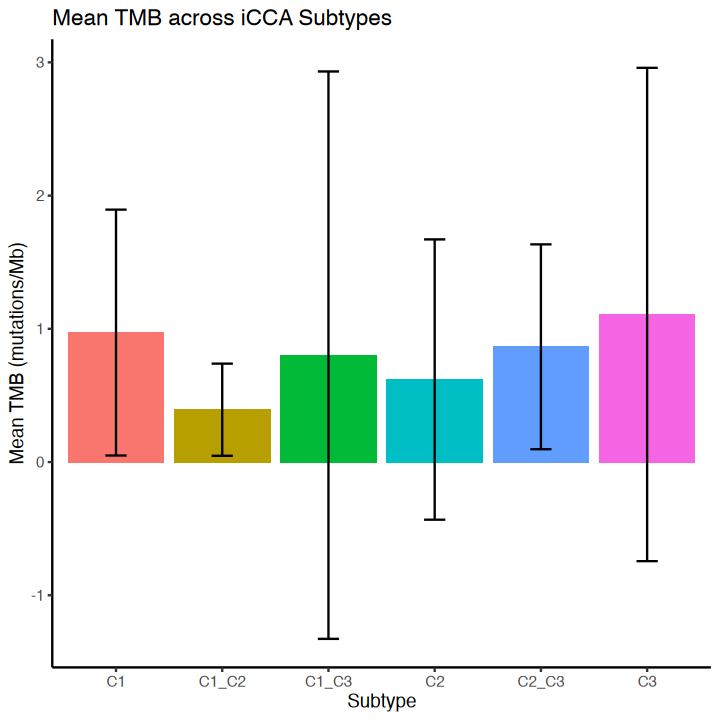

In [58]:
library(ggplot2)
library(dplyr)

# 1. 首先计算每个亚型的均值和标准差
summary_data <- clinical_data_for_plot %>%
  group_by(Ensemble) %>%
  summarise(
    mean_tmb = mean(total_perMB, na.rm = TRUE),
    sd_tmb = sd(total_perMB, na.rm = TRUE)
  )

# 2. 绘制条形图
ggplot(summary_data, aes(x = Ensemble, y = mean_tmb, fill = Ensemble)) +
  geom_bar(stat = "identity", position = position_dodge()) +
  
  # 添加误差线 (均值 ± 1个标准差)
  geom_errorbar(
    aes(ymin = mean_tmb - sd_tmb, ymax = mean_tmb + sd_tmb),
    width = 0.2,
    position = position_dodge(0.9)
  ) +
  
  labs(
    title = "Mean TMB across iCCA Subtypes",
    x = "Subtype",
    y = "Mean TMB (mutations/Mb)"
  ) +
  theme_classic() +
  theme(legend.position = "none")

# **Protein**

In [11]:
library(limma)
library(dplyr)
library(ggplot2)
library(ggrepel)
library(clusterProfiler)
library(org.Hs.eg.db)
library(writexl)         # 用于将结果写入多页Excel

In [31]:
protein <- read.csv(file = "./0-Data/0-Data-corrected-protein.csv",row.names = 1)
dim(protein)
head(protein)

[1] 8296  298

,X115,X117,X121,X123,X125,X133,X135,X137,X141,X145,...,CCA.80,CCA.82,CCA.85,CCA.89,CCA.90,CCA.91,CCA.93,CCA.94,CCA.95,CCA.98
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1-Mar,3.1384564,0.8706699,0.14056241,1.5345069,-0.7081415,0.1506957,-1.0347897,0.10437772,-0.7162476,0.1280358,...,-0.05748693,-0.3139260,-0.2721762,-0.3139260,-0.3139260,-0.31392597,-0.31392597,-0.0246579,-0.3139260,3.16264062
1-Sep,-0.2688108,-0.8639683,-0.02903576,0.0374228,-0.3743786,1.3348989,-0.6958552,0.07138807,-0.6512474,-0.2398088,...,-0.27107007,-0.3151318,0.1111752,0.2151971,-0.1134989,-0.31513180,-0.31513180,-0.1480897,1.9026639,-0.05396275
10-Sep,-0.3539828,1.0171749,0.87220542,-0.1167739,0.7928682,-0.4137493,-0.1039814,1.49972889,-0.4708291,0.8741091,...,-0.60604059,-0.1813856,-0.5568200,0.5497384,-0.3962590,0.06918692,-0.18104612,-0.5445431,0.8103248,-0.16599706
11-Sep,4.9194121,2.0747315,4.00125524,0.7944405,1.8756259,4.5729542,4.8903437,3.06515681,5.9058327,3.8977205,...,-0.42105606,7.9554454,0.2847590,2.2423199,6.3706208,1.93029716,4.05630668,3.1416764,4.9480262,1.83969055
15-Sep,0.6184967,6.3061826,1.71559410,5.0074285,2.9666833,1.2994895,2.2334499,1.53730941,3.4273133,3.2402421,...,17.70000414,6.7151872,5.8817229,5.0988536,-2.8957029,13.91257892,3.75136728,0.4321360,3.9726530,2.62787516
2-Mar,4.7671228,6.8301253,3.24270937,5.5093142,-0.2257457,0.8293558,-1.2262765,2.26071464,-0.9787906,2.5891553,...,6.58457094,-0.7454705,1.4576068,0.3295853,-0.4505965,1.20271948,-0.08359184,5.0910359,0.2063667,7.90645052


In [32]:
# 假设你的数据框名为protein
# 处理列名：移除开头的X并将.替换为#
names(protein) <- gsub("^X", "", names(protein))  # 移除开头的X
names(protein) <- gsub("\\.", "#", names(protein))  # 将.替换为#

# 检查结果
head(names(protein))

[1] "115" "117" "121" "123" "125" "133"

In [33]:
head(protein)

,115,117,121,123,125,133,135,137,141,145,...,CCA#80,CCA#82,CCA#85,CCA#89,CCA#90,CCA#91,CCA#93,CCA#94,CCA#95,CCA#98
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1-Mar,3.1384564,0.8706699,0.14056241,1.5345069,-0.7081415,0.1506957,-1.0347897,0.10437772,-0.7162476,0.1280358,...,-0.05748693,-0.3139260,-0.2721762,-0.3139260,-0.3139260,-0.31392597,-0.31392597,-0.0246579,-0.3139260,3.16264062
1-Sep,-0.2688108,-0.8639683,-0.02903576,0.0374228,-0.3743786,1.3348989,-0.6958552,0.07138807,-0.6512474,-0.2398088,...,-0.27107007,-0.3151318,0.1111752,0.2151971,-0.1134989,-0.31513180,-0.31513180,-0.1480897,1.9026639,-0.05396275
10-Sep,-0.3539828,1.0171749,0.87220542,-0.1167739,0.7928682,-0.4137493,-0.1039814,1.49972889,-0.4708291,0.8741091,...,-0.60604059,-0.1813856,-0.5568200,0.5497384,-0.3962590,0.06918692,-0.18104612,-0.5445431,0.8103248,-0.16599706
11-Sep,4.9194121,2.0747315,4.00125524,0.7944405,1.8756259,4.5729542,4.8903437,3.06515681,5.9058327,3.8977205,...,-0.42105606,7.9554454,0.2847590,2.2423199,6.3706208,1.93029716,4.05630668,3.1416764,4.9480262,1.83969055
15-Sep,0.6184967,6.3061826,1.71559410,5.0074285,2.9666833,1.2994895,2.2334499,1.53730941,3.4273133,3.2402421,...,17.70000414,6.7151872,5.8817229,5.0988536,-2.8957029,13.91257892,3.75136728,0.4321360,3.9726530,2.62787516
2-Mar,4.7671228,6.8301253,3.24270937,5.5093142,-0.2257457,0.8293558,-1.2262765,2.26071464,-0.9787906,2.5891553,...,6.58457094,-0.7454705,1.4576068,0.3295853,-0.4505965,1.20271948,-0.08359184,5.0910359,0.2063667,7.90645052


In [34]:
# 确保protein的列与sample_info中的样本顺序一致
common_samples <- intersect(colnames(protein), sample_cluster$Sample)
length(common_samples)
protein <- protein[, common_samples]
sample_info <- sample_cluster[sample_cluster$Sample %in% common_samples, ]

# 使用sample_info中的亚型信息创建subtypes因子
subtypes <- factor(sample_info$Ensemble)
length(subtypes)

[1] 292

[1] 292

In [35]:
all_proteins_in_matrix <- rownames(protein) # 定义背景基因集
length(all_proteins_in_matrix)

[1] 8296

In [42]:
# 准备通路数据库
full_msigdb_df <- readRDS("/Users/luye/Data/Sig/msigdb.2024.1.Hs.rds")
hallmark_gmt <- full_msigdb_df %>% 
  filter(gs_collection == "H") %>%
  dplyr::select(gs_name, gene_symbol = db_gene_symbol)
KEGG <- read.csv(file = "/Users/luye/Data/Sig/hsaMetaGenes.csv")
m_t2g <- KEGG[, c(1,3)]
colnames(m_t2g) <- c("gs_name", "gene_symbol")
reactome_gmt <- full_msigdb_df %>%
  filter(gs_collection == "C2", gs_subcollection == "CP:REACTOME") %>%
  dplyr::select(gs_name, gene_symbol = db_gene_symbol)

# 确保加载必要的包
library(limma)
library(clusterProfiler)
library(org.Hs.eg.db)
library(dplyr)     # 显式加载dplyr
library(ggplot2)
library(writexl)
library(ggrepel)  # 火山图标签需要

# 数据质量检查
cat("蛋白质数据维度:", dim(protein), "\n")
cat("缺失值比例:", sum(is.na(protein))/prod(dim(protein)), "\n")
cat("亚型变量水平:", levels(subtypes), "\n")

# 确保设置universe
all_proteins_in_matrix <- rownames(protein)

# 创建结果目录
dir.create("results_figures", showWarnings = FALSE)

# --- 创建limma设计矩阵 ---
design <- model.matrix(~0 + subtypes)
colnames(design) <- levels(subtypes)

# 重要：检查设计矩阵维度
cat("设计矩阵维度:", dim(design), "\n") # 应该是 [样本数 x 亚型数]
cat("蛋白质矩阵维度:", dim(protein), "\n") # [蛋白质数 x 样本数]

# 创建一个列表来存储所有分析的结果
all_analysis_results <- list()
diff_summary_all <- data.frame()

# --- 开始对每个亚型进行"一对多"的循环分析 ---
subtype_levels <- levels(subtypes)

for (current_subtype in subtype_levels) {
  
  cat(paste0("\n\n--- 开始分析亚型: ", current_subtype, " ---\n"))
  
  # --- 动态创建对比矩阵并进行差异分析 ---
  tryCatch({
    other_subtypes <- setdiff(subtype_levels, current_subtype)
    contrast_formula <- paste0(current_subtype, " - (", paste(other_subtypes, collapse = " + "), ")/", length(other_subtypes))
    
    cat("对比公式:", contrast_formula, "\n")
    
    contrast_matrix <- makeContrasts(contrasts = contrast_formula, levels = design)
    
    # 检查protein和design的行列匹配问题
    if(ncol(protein) != nrow(design)) {
      cat("错误: protein列数", ncol(protein), "与design行数", nrow(design), "不匹配\n")
      
      # 尝试调整protein的列顺序以匹配design的行顺序
      if(!is.null(rownames(design)) && !is.null(colnames(protein))) {
        common_samples <- intersect(rownames(design), colnames(protein))
        if(length(common_samples) > 0) {
          cat("找到", length(common_samples), "个共同样本，调整数据...\n")
          protein <- protein[, common_samples]
          design <- design[common_samples, ]
          cat("调整后: protein列数", ncol(protein), "design行数", nrow(design), "\n")
        } else {
          cat("未找到共同样本，无法继续分析\n")
          next
        }
      } else {
        cat("无法自动调整，请手动检查数据结构\n")
        next
      }
    }
    
    fit <- lmFit(protein, design)
    fit2 <- contrasts.fit(fit, contrast_matrix)
    fit_bayes <- eBayes(fit2)
    
    # 提取当前比较的差异蛋白结果
    diff_results <- topTable(fit_bayes, number = Inf)
    
    # 重要修改1: 添加蛋白质/基因名称列
    diff_results$ProteinID <- rownames(diff_results)
    
    # 重新排列列顺序，使ProteinID成为第一列
    # 修复: 明确使用dplyr::select而不是基本的select
    diff_results <- diff_results %>%
      dplyr::select(ProteinID, everything())
    
    # 添加差异表达信息列
    diff_results$Regulation <- ifelse(diff_results$adj.P.Val < 0.05,
                                     ifelse(diff_results$logFC > 1, "Up",
                                            ifelse(diff_results$logFC < -1, "Down", "NS")),
                                     "NS")
    
    # 将差异分析结果存入列表
    all_analysis_results[[paste0("Diff_", current_subtype, "_vs_Others")]] <- diff_results
    
    # 创建差异表达摘要
    diff_summary <- data.frame(
      Subtype = current_subtype,
      Total_Proteins = nrow(diff_results),
      Up_Significant = sum(diff_results$Regulation == "Up"),
      Down_Significant = sum(diff_results$Regulation == "Down"),
      Total_Significant = sum(diff_results$Regulation %in% c("Up", "Down"))
    )
    
    diff_summary_all <- rbind(diff_summary_all, diff_summary)
    all_analysis_results[["Differential_Summary"]] <- diff_summary_all
    

    # 创建火山图并添加显著蛋白的名称
    volcano_plot_with_labels <- function(diff_results, current_subtype, label_top_n = 10) {
      # 为显著上调蛋白添加标签
      top_up <- diff_results %>%
        dplyr::filter(Regulation == "Up") %>%
        dplyr::top_n(label_top_n, abs(logFC))
    
      # 为显著下调蛋白添加标签
      top_down <- diff_results %>%
        dplyr::filter(Regulation == "Down") %>%
        dplyr::top_n(label_top_n, abs(logFC))
    
      # 合并需要标签的蛋白
      to_label <- rbind(top_up, top_down)
    
      # 创建火山图
      volcano_p <- ggplot(diff_results, aes(x = logFC, y = -log10(adj.P.Val), color = Regulation)) +
        geom_point(alpha = 0.7) +
        scale_color_manual(values = c("Up" = "red", "Down" = "blue", "NS" = "grey")) +
        theme_minimal() +
        labs(title = paste0("Volcano Plot - ", current_subtype, " vs Others"),
            x = "Log2 Fold Change", y = "-log10(Adjusted P-value)") +
        geom_hline(yintercept = -log10(0.05), linetype = "dashed") +
        geom_vline(xintercept = c(-1, 1), linetype = "dashed")
    
      # 添加蛋白名称标签
      if(nrow(to_label) > 0) {
        volcano_p <- volcano_p +
          ggrepel::geom_text_repel(
            data = to_label,
            aes(label = ProteinID),
            size = 3,
            box.padding = 0.5,
            point.padding = 0.3,
            force = 3,
            segment.color = "grey50",
            max.overlaps = 20
          )
      }
    
      return(volcano_p)
    }
    volcano_p <- volcano_plot_with_labels(diff_results, current_subtype, label_top_n = 15)
    ggsave(paste0("results_figures/Volcano_", current_subtype, ".pdf"), volcano_p, width = 10, height = 8)

    # --- 提取上调和下调蛋白列表用于富集分析 ---
    upregulated_proteins <- diff_results$ProteinID[diff_results$Regulation == "Up"]
    downregulated_proteins <- diff_results$ProteinID[diff_results$Regulation == "Down"]
    
    # 为GSEA准备ranked gene list
    gene_list <- diff_results$logFC
    names(gene_list) <- diff_results$ProteinID
    gene_list <- sort(gene_list, decreasing = TRUE)
    
    # 记录上下调蛋白的logFC用于网络图
    upregulated_logfc <- diff_results$logFC[diff_results$Regulation == "Up"]
    names(upregulated_logfc) <- upregulated_proteins
    
    downregulated_logfc <- diff_results$logFC[diff_results$Regulation == "Down"]
    names(downregulated_logfc) <- downregulated_proteins
    
    cat(paste0("找到 ", length(upregulated_proteins), " 个上调蛋白, ", 
               length(downregulated_proteins), " 个下调蛋白\n"))
    
    # --- 对上调蛋白进行富集分析 ---
    if (length(upregulated_proteins) >= 5) {
      cat("开始上调蛋白的富集分析...\n")
      
      # GO富集分析
      tryCatch({
        go_res <- enrichGO(
          gene = upregulated_proteins, universe = all_proteins_in_matrix,
          OrgDb = org.Hs.eg.db, keyType = 'SYMBOL', ont = "BP",
          pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2
        )
        if (!is.null(go_res) && nrow(go_res) > 0) {
          all_analysis_results[[paste0("GO_Upreg_in_", current_subtype)]] <- as.data.frame(go_res)
          
          # 保存GO富集气泡图
          p1 <- dotplot(go_res, showCategory=15, title=paste0("GO BP - Up in ", current_subtype))
          ggsave(paste0("results_figures/GO_Upreg_", current_subtype, ".pdf"), p1, width=12, height=8)
          
          # 保存GO网络图
          p2 <- cnetplot(go_res, categorySize="pvalue", showCategory=5, foldChange=upregulated_logfc)
          ggsave(paste0("results_figures/GO_Network_Up_", current_subtype, ".pdf"), p2, width=12, height=10)
        }
      }, error = function(e) {
        cat(paste0("GO富集分析错误: ", e$message, "\n"))
      })
      
      # 其他富集分析代码保持不变...
      # KEGG富集分析
      tryCatch({
        kegg_res <- enricher(
          gene = upregulated_proteins, universe = all_proteins_in_matrix,
          pvalueCutoff = 0.05, pAdjustMethod = "BH", qvalueCutoff = 0.2,
          TERM2GENE = m_t2g
        )
        if (!is.null(kegg_res) && nrow(kegg_res) > 0) {
          all_analysis_results[[paste0("KEGG_Upreg_in_", current_subtype)]] <- as.data.frame(kegg_res)
          
          # 保存KEGG富集图
          p3 <- dotplot(kegg_res, showCategory=15, title=paste0("KEGG - Up in ", current_subtype))
          ggsave(paste0("results_figures/KEGG_Upreg_", current_subtype, ".pdf"), p3, width=12, height=8)
        }
      }, error = function(e) {
        cat(paste0("KEGG富集分析错误: ", e$message, "\n"))
      })
      
      # HALLMARK富集分析
      tryCatch({
        hallmark_res <- enricher(
          gene = upregulated_proteins, universe = all_proteins_in_matrix,
          TERM2GENE = hallmark_gmt, pvalueCutoff = 0.05, qvalueCutoff = 0.2
        )
        if (!is.null(hallmark_res) && nrow(hallmark_res) > 0) {
          all_analysis_results[[paste0("HALLMARK_Upreg_in_", current_subtype)]] <- as.data.frame(hallmark_res)
          
          # 保存HALLMARK富集图
          p4 <- dotplot(hallmark_res, showCategory=15, title=paste0("HALLMARK - Up in ", current_subtype))
          ggsave(paste0("results_figures/HALLMARK_Upreg_", current_subtype, ".pdf"), p4, width=12, height=8)
        }
      }, error = function(e) {
        cat(paste0("HALLMARK富集分析错误: ", e$message, "\n"))
      })
      
      # Reactome富集分析
      tryCatch({
        reactome_res <- enricher(
          gene = upregulated_proteins, universe = all_proteins_in_matrix,
          TERM2GENE = reactome_gmt, pvalueCutoff = 0.05, qvalueCutoff = 0.2
        )
        if (!is.null(reactome_res) && nrow(reactome_res) > 0) {
          all_analysis_results[[paste0("REACTOME_Upreg_in_", current_subtype)]] <- as.data.frame(reactome_res)
          
          # 保存Reactome富集图
          p5 <- dotplot(reactome_res, showCategory=15, title=paste0("REACTOME - Up in ", current_subtype))
          ggsave(paste0("results_figures/REACTOME_Upreg_", current_subtype, ".pdf"), p5, width=12, height=8)
        }
      }, error = function(e) {
        cat(paste0("Reactome富集分析错误: ", e$message, "\n"))
      })
    }
    
    # --- 重要修改2: 对下调蛋白进行富集分析 ---
    if (length(downregulated_proteins) >= 5) {
      cat("开始下调蛋白的富集分析...\n")
      
      # GO富集分析 - 下调蛋白
      tryCatch({
        go_down_res <- enrichGO(
          gene = downregulated_proteins, universe = all_proteins_in_matrix,
          OrgDb = org.Hs.eg.db, keyType = 'SYMBOL', ont = "BP",
          pAdjustMethod = "BH", pvalueCutoff = 0.05, qvalueCutoff = 0.2
        )
        if (!is.null(go_down_res) && nrow(go_down_res) > 0) {
          all_analysis_results[[paste0("GO_Downreg_in_", current_subtype)]] <- as.data.frame(go_down_res)
          
          # 保存GO富集气泡图 - 下调
          p1_down <- dotplot(go_down_res, showCategory=15, title=paste0("GO BP - Down in ", current_subtype))
          ggsave(paste0("results_figures/GO_Downreg_", current_subtype, ".pdf"), p1_down, width=12, height=8)
          
          # 保存GO网络图 - 下调
          p2_down <- cnetplot(go_down_res, categorySize="pvalue", showCategory=5, foldChange=downregulated_logfc)
          ggsave(paste0("results_figures/GO_Network_Down_", current_subtype, ".pdf"), p2_down, width=12, height=10)
        }
      }, error = function(e) {
        cat(paste0("下调蛋白GO富集分析错误: ", e$message, "\n"))
      })
      
      # 其他下调蛋白富集分析保持不变...
      # KEGG富集分析 - 下调蛋白
      tryCatch({
        kegg_down_res <- enricher(
          gene = downregulated_proteins, universe = all_proteins_in_matrix,
          pvalueCutoff = 0.05, pAdjustMethod = "BH", qvalueCutoff = 0.2,
          TERM2GENE = m_t2g
        )
        if (!is.null(kegg_down_res) && nrow(kegg_down_res) > 0) {
          all_analysis_results[[paste0("KEGG_Downreg_in_", current_subtype)]] <- as.data.frame(kegg_down_res)
          
          # 保存KEGG富集图 - 下调
          p3_down <- dotplot(kegg_down_res, showCategory=15, title=paste0("KEGG - Down in ", current_subtype))
          ggsave(paste0("results_figures/KEGG_Downreg_", current_subtype, ".pdf"), p3_down, width=12, height=8)
        }
      }, error = function(e) {
        cat(paste0("下调蛋白KEGG富集分析错误: ", e$message, "\n"))
      })
      
      # HALLMARK富集分析 - 下调蛋白
      tryCatch({
        hallmark_down_res <- enricher(
          gene = downregulated_proteins, universe = all_proteins_in_matrix,
          TERM2GENE = hallmark_gmt, pvalueCutoff = 0.05, qvalueCutoff = 0.2
        )
        if (!is.null(hallmark_down_res) && nrow(hallmark_down_res) > 0) {
          all_analysis_results[[paste0("HALLMARK_Downreg_in_", current_subtype)]] <- as.data.frame(hallmark_down_res)
          
          # 保存HALLMARK富集图 - 下调
          p4_down <- dotplot(hallmark_down_res, showCategory=15, title=paste0("HALLMARK - Down in ", current_subtype))
          ggsave(paste0("results_figures/HALLMARK_Downreg_", current_subtype, ".pdf"), p4_down, width=12, height=8)
        }
      }, error = function(e) {
        cat(paste0("下调蛋白HALLMARK富集分析错误: ", e$message, "\n"))
      })
      
      # Reactome富集分析 - 下调蛋白
      tryCatch({
        reactome_down_res <- enricher(
          gene = downregulated_proteins, universe = all_proteins_in_matrix,
          TERM2GENE = reactome_gmt, pvalueCutoff = 0.05, qvalueCutoff = 0.2
        )
        if (!is.null(reactome_down_res) && nrow(reactome_down_res) > 0) {
          all_analysis_results[[paste0("REACTOME_Downreg_in_", current_subtype)]] <- as.data.frame(reactome_down_res)
          
          # 保存Reactome富集图 - 下调
          p5_down <- dotplot(reactome_down_res, showCategory=15, title=paste0("REACTOME - Down in ", current_subtype))
          ggsave(paste0("results_figures/REACTOME_Downreg_", current_subtype, ".pdf"), p5_down, width=12, height=8)
        }
      }, error = function(e) {
        cat(paste0("下调蛋白Reactome富集分析错误: ", e$message, "\n"))
      })
    }
    
    # --- 添加GSEA分析 ---
    # GSEA仍然可以进行，因为它不依赖于预先筛选的基因集
    tryCatch({
      hallmark_gsea <- GSEA(
        geneList = gene_list,
        TERM2GENE = hallmark_gmt,
        pvalueCutoff = 0.05,
        pAdjustMethod = "BH"
      )
      
      if (!is.null(hallmark_gsea) && nrow(hallmark_gsea) > 0) {
        all_analysis_results[[paste0("HALLMARK_GSEA_", current_subtype)]] <- as.data.frame(hallmark_gsea)
        
        # 保存GSEA图形
        top_n_pathways <- min(5, nrow(hallmark_gsea))
        if (top_n_pathways > 0) {
          p_gsea <- gseaplot2(hallmark_gsea, geneSetID=1:top_n_pathways, 
                            title=paste0("GSEA HALLMARK - ", current_subtype))
          ggsave(paste0("results_figures/GSEA_HALLMARK_", current_subtype, ".pdf"), p_gsea, width=12, height=8)
        }
      }
    }, error = function(e) {
      cat(paste0("HALLMARK GSEA分析错误: ", e$message, "\n"))
    })
    
  }, error = function(e) {
    cat(paste0("在处理亚型 ", current_subtype, " 时遇到错误: ", e$message, "\n"))
  })
  
  cat(paste0("亚型 ", current_subtype, " 分析完成。\n\n"))
}

# --- 将所有结果保存到Excel文件中 ---
if (length(all_analysis_results) > 0) {
  # 创建结果比较图目录
  dir.create("Enrichment_Comparison", showWarnings = FALSE)
  
  # 添加不同亚型的富集结果比较图
  # 创建富集分析比较图函数
  create_enrichment_comparison <- function(all_analysis_results, pathway_type = "GO", regulation = "Upreg") {
    # 选择特定类型的富集结果
    pattern <- paste0(pathway_type, "_", regulation)
    enrichment_results <- all_analysis_results[grep(pattern, names(all_analysis_results))]
    
    if(length(enrichment_results) == 0) {
      cat(paste0("未找到", pathway_type, " ", regulation, "类型的富集结果\n"))
      return(NULL)
    }
    
    # 添加亚型名到每个数据框中，并合并
    combined_df <- bind_rows(enrichment_results, .id = "Subtype") %>%
      # 清理亚型名
      mutate(Subtype = gsub(paste0(pathway_type, "_", regulation, "_in_"), "", Subtype))
    
    # 只保留显著富集的通路
    combined_df <- combined_df %>% filter(p.adjust < 0.05)
    
    if(nrow(combined_df) == 0) {
      cat(paste0("没有显著富集的", pathway_type, " ", regulation, "通路\n"))
      return(NULL)
    }
    
    # 筛选出每个亚型Top 5的通路，合并后取唯一值，作为要展示的通路列表
    top_pathways <- combined_df %>%
      group_by(Subtype) %>%
      top_n(-5, wt = p.adjust) %>%
      pull(Description) %>%
      unique()
    
    # 如果通路太多，只取前20个
    if(length(top_pathways) > 20) {
      # 按在不同亚型中出现频率排序
      pathway_counts <- combined_df %>%
        filter(Description %in% top_pathways) %>%
        group_by(Description) %>%
        summarise(count = n(), avg_p = mean(p.adjust)) %>%
        arrange(desc(count), avg_p)
      
      top_pathways <- pathway_counts$Description[1:20]
    }
    
    # 筛选出这些Top通路在所有亚型中的结果
    plot_df <- combined_df %>%
      filter(Description %in% top_pathways) %>%
      mutate(
        # 创建数值型GeneRatio
        GeneRatio_val = sapply(GeneRatio, function(x) {
          parts <- strsplit(x, "/")[[1]]
          as.numeric(parts[1]) / as.numeric(parts[2])
        }),
        # 基因数量
        Count = as.numeric(sapply(strsplit(GeneRatio, "/"), `[`, 1))
      )
    
    # 简化过长的通路名称
    plot_df <- plot_df %>% 
      mutate(Description = stringr::str_wrap(Description, width = 50))
    
    # 绘制富集热图
    p_heatmap <- ggplot(plot_df, aes(x = Subtype, y = reorder(Description, -GeneRatio_val))) +
      geom_point(aes(size = Count, color = p.adjust)) +
      scale_color_gradientn(
        colors = c("red", "orange", "blue"), 
        name = "Adjusted\np-value",
        trans = "log10",
        labels = scales::scientific
      ) +
      scale_size_continuous(range = c(3, 12), name = "Gene Count") +
      labs(
        x = "Subtype", 
        y = "Pathway", 
        title = paste0(pathway_type, " Pathways ", 
                      ifelse(regulation == "Upreg", "Upregulated", "Downregulated"), 
                      " Across Subtypes")
      ) +
      theme_bw() +
      theme(
        axis.text.x = element_text(angle = 45, hjust = 1, size = 11),
        axis.text.y = element_text(size = 10),
        legend.position = "right",
        plot.title = element_text(size = 14, face = "bold"),
        panel.grid.major = element_line(color = "grey90"),
        panel.grid.minor = element_blank()
      )
    
    # 返回图形对象
    return(p_heatmap)
  }
  
  # 为各种富集类型创建比较图
  pathway_types <- c("GO", "KEGG", "HALLMARK", "REACTOME")
  regulation_types <- c("Upreg", "Downreg")
  
  for(pathway in pathway_types) {
    for(regulation in regulation_types) {
      cat(paste0("创建", pathway, " ", regulation, "富集比较图...\n"))
      
      p <- create_enrichment_comparison(all_analysis_results, pathway, regulation)
      
      if(!is.null(p)) {
        filename <- paste0("Enrichment_Comparison/", pathway, "_", regulation, "_Comparison.pdf")
        ggsave(filename, p, width = 12, height = 10)
        cat(paste0("保存到: ", filename, "\n"))
      }
    }
  }
  
  # 保存Excel文件
  write_xlsx(all_analysis_results, path = "Subtype_Proteomics_Analysis_Results.xlsx")
  cat("--- 全部分析完成！结果已保存到 'Subtype_Proteomics_Analysis_Results.xlsx' ---\n")
  cat("--- 图形结果已保存在 'results_figures' 目录中 ---\n")
  cat("--- 富集比较图已保存在 'Enrichment_Comparison' 目录中 ---\n")
} else {
  cat("--- 未发现任何显著的差异或富集结果。 ---\n")
}

<U+86CB><U+767D><U+8D28><U+6570><U+636E><U+7EF4><U+5EA6>: 8296 292 
<U+7F3A><U+5931><U+503C><U+6BD4><U+4F8B>: 0 
<U+4E9A><U+578B><U+53D8><U+91CF><U+6C34><U+5E73>: C1 C1_C2 C1_C3 C2 C2_C3 C3 
<U+8BBE><U+8BA1><U+77E9><U+9635><U+7EF4><U+5EA6>: 292 6 
<U+86CB><U+767D><U+8D28><U+77E9><U+9635><U+7EF4><U+5EA6>: 8296 292 


--- <U+5F00><U+59CB><U+5206><U+6790><U+4E9A><U+578B>: C1 ---
<U+5BF9><U+6BD4><U+516C><U+5F0F>: C1 - (C1_C2 + C1_C3 + C2 + C2_C3 + C3)/5 


Warning message:
"ggrepel: 4 unlabeled data points (too many overlaps). Consider increasing max.overlaps"


<U+627E><U+5230> 259 <U+4E2A><U+4E0A><U+8C03><U+86CB><U+767D>, 118 <U+4E2A><U+4E0B><U+8C03><U+86CB><U+767D>
<U+5F00><U+59CB><U+4E0A><U+8C03><U+86CB><U+767D><U+7684><U+5BCC><U+96C6><U+5206><U+6790>...


Warning message in cnetplot.enrichResult(x, ...):
"Use 'color.params = list(foldChange = your_value)' instead of 'foldChange'.
 The foldChange parameter will be removed in the next version."


GO<U+5BCC><U+96C6><U+5206><U+6790><U+9519><U+8BEF>: Problem while converting geom to grob.
<U+5F00><U+59CB><U+4E0B><U+8C03><U+86CB><U+767D><U+7684><U+5BCC><U+96C6><U+5206><U+6790>...


Warning message in cnetplot.enrichResult(x, ...):
"Use 'color.params = list(foldChange = your_value)' instead of 'foldChange'.
 The foldChange parameter will be removed in the next version."


... (23 outputs left out)

Warning message in cnetplot.enrichResult(x, ...):
"Use 'color.params = list(foldChange = your_value)' instead of 'foldChange'.
 The foldChange parameter will be removed in the next version."


<U+4E0B><U+8C03><U+86CB><U+767D>GO<U+5BCC><U+96C6><U+5206><U+6790><U+9519><U+8BEF>: Problem while converting geom to grob.


using 'fgsea' for GSEA analysis, please cite Korotkevich et al (2019).


preparing geneSet collections...

GSEA analysis...

leading edge analysis...

done...



HALLMARK GSEA<U+5206><U+6790><U+9519><U+8BEF>: could not find function "gseaplot2"
<U+4E9A><U+578B> C3 <U+5206><U+6790><U+5B8C><U+6210><U+3002>

<U+521B><U+5EFA>GO Upreg<U+5BCC><U+96C6><U+6BD4><U+8F83><U+56FE>...
<U+4FDD><U+5B58><U+5230>: Enrichment_Comparison/GO_Upreg_Comparison.pdf
<U+521B><U+5EFA>GO Downreg<U+5BCC><U+96C6><U+6BD4><U+8F83><U+56FE>...
<U+4FDD><U+5B58><U+5230>: Enrichment_Comparison/GO_Downreg_Comparison.pdf
<U+521B><U+5EFA>KEGG Upreg<U+5BCC><U+96C6><U+6BD4><U+8F83><U+56FE>...
<U+4FDD><U+5B58><U+5230>: Enrichment_Comparison/KEGG_Upreg_Comparison.pdf
<U+521B><U+5EFA>KEGG Downreg<U+5BCC><U+96C6><U+6BD4><U+8F83><U+56FE>...
<U+4FDD><U+5B58><U+5230>: Enrichment_Comparison/KEGG_Downreg_Comparison.pdf
<U+521B><U+5EFA>HALLMARK Upreg<U+5BCC><U+96C6><U+6BD4><U+8F83><U+56FE>...
<U+4FDD><U+5B58><U+5230>: Enrichment_Comparison/HALLMARK_Upreg_Comparison.pdf
<U+521B><U+5EFA>HALLMARK Downreg<U+5BCC><U+96C6><U+6BD4><U+8F83><U+56FE>...
<U+4FDD><U+5B58><U+5230>: Enrichment_Comparison/HAL

# **Multi-omics**

In [4]:
library(iClusterPlus)
library(MOFA2)
library(sva)
library(cluster)
library(ggplot2)
library(tidyverse)

## **mRNA + Protein + CNV**

In [5]:
load(file = "./0-Data/0-Data-rnaseq.Rdata")
load(file = "./0-Data/0-Data-protein.Rdata")
ls()

[1] "corrected_prot_matrix" "log2tpm_2019Ahn"       "log2tpm_2022Dong"     
 [4] "log2tpm_2023Deng"      "log2tpm_2023Jeon"      "log2tpm_2023Lee"      
 [7] "log2tpm_2024Fan"       "log2tpm_tcga"          "pro_2022Dong"         
[10] "pro_2023Deng"          "pro_tcga"              "sample_cluster"       
[13] "sample_info"           "tpm_2019Ahn"           "tpm_2022Dong"         
[16] "tpm_2023Deng"          "tpm_2023Jeon"          "tpm_2023Lee"          
[19] "tpm_2024Fan"           "tpm_tcga"

In [6]:
cnv <- read.table(file = "./0-Data/2022Dong/WES_CNV_GISTIC2_raw.txt", header = T,sep = "\t")
dim(cnv)
head(cnv)

[1] 23109   256

,Gene.Symbol,Gene.ID,Cytoband,X111,X113,X115,X117,X121,X123,X125,...,X995,X155,X147,X151,X525,X523,X521,X517,X515,X511
,<chr>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,DDX11L1|chr1,100287102,1p36.33,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
2,FAM138A|chr1,645520,1p36.33,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
3,FAM138F|chr1,641702,1p36.33,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
4,LOC100132062|chr1,100132062,1p36.33,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
5,LOC100132287|chr1,100132287,1p36.33,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
6,LOC100133331|chr1,100133331,1p36.33,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022


In [7]:
# 提取基因名
gene_names <- sub("\\|.*", "", cnv$Gene.Symbol)
# 找到重复的基因名
dup_genes <- gene_names[duplicated(gene_names)]
# 只保留第一个出现的基因
cnv_unique <- cnv[!duplicated(gene_names), ]
# 设置行名
rownames(cnv_unique) <- sub("\\|.*", "", cnv_unique$Gene.Symbol)
# 保留数值矩阵部分
cnv_mat <- as.matrix(cnv_unique[, -(1:3)])
colnames(cnv_mat) <- sub("^X", "", colnames(cnv_mat))

In [8]:
dim(cnv_mat)
head(cnv_mat)

[1] 23082   253

,111,113,115,117,121,123,125,127,131,133,...,995,155,147,151,525,523,521,517,515,511
DDX11L1,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,0.294,-0.113,-0.233,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
FAM138A,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,0.294,-0.113,-0.233,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
FAM138F,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,0.294,-0.113,-0.233,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
LOC100132062,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,0.294,-0.113,-0.233,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
LOC100132287,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,0.294,-0.113,-0.233,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022
LOC100133331,0.042,-0.44,-0.194,-0.176,-0.455,0.01,0.19,0.294,-0.113,-0.233,...,-0.36,-0.17,-0.075,-0.035,0.096,-0.543,-0.48,-0.121,-0.253,-0.022


In [9]:
dim(log2tpm_2022Dong)
head(log2tpm_2022Dong)

[1] 15511   255

,111,113,115,117,121,123,125,127,131,133,...,965,971,973,975,977,981,983,987,993,995
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
B2M,13.430168,12.32590,12.404459,12.45580,12.45989,14.63052,13.25311,14.57845,14.66255,14.24210,...,14.33782,13.69486,13.303849,14.90831,13.86014,13.74693,12.76609,13.73268,13.63197,13.24348
C3,14.341027,14.49220,15.295039,15.13160,10.92308,13.86242,12.47226,7.95043,10.18280,11.79305,...,13.66771,12.63277,14.697905,13.37304,13.72153,13.78406,14.23433,13.45836,13.44036,12.07106
HIST1H4J,13.555246,11.32292,13.968910,13.36368,13.15464,12.83805,14.90676,13.26796,13.59223,14.01480,...,13.03658,14.67703,10.829429,13.51716,13.45496,13.59778,11.56529,13.67845,12.47192,10.79059
TMSB4X,9.516253,11.39659,10.610273,11.25094,13.59468,13.02852,12.31775,12.08067,13.74150,13.76952,...,11.18926,10.23412,11.259799,12.72126,12.40877,13.58365,12.30764,12.65264,12.64065,13.27073
TPT1,13.257300,13.32464,12.339304,13.03383,13.27284,12.52888,13.23910,13.09535,12.80871,13.26466,...,13.59988,12.19750,11.798541,12.92681,13.10811,12.77667,13.21689,12.58143,13.44632,13.33780
SPP1,12.691186,13.31864,8.997304,11.87468,13.15220,12.99333,11.61442,14.19392,11.37294,10.74903,...,11.00987,10.40746,9.717406,13.91342,14.31464,12.47973,14.24377,13.76963,14.24417,12.70528


In [10]:
library(dplyr)

# 过滤掉Gene为缺失的行
pro_2022Dong_nona <- pro_2022Dong %>% filter(!is.na(Gene) & Gene != "")

# 合并重复基因（建议用最新写法）
pro_2022Dong_agg <- pro_2022Dong_nona %>%
  group_by(Gene) %>%
  summarise(across(everything(), \(x) mean(x, na.rm = TRUE)))

# 转为data.frame，设置行名
pro_2022Dong_agg <- as.data.frame(pro_2022Dong_agg)
rownames(pro_2022Dong_agg) <- pro_2022Dong_agg$Gene
pro_2022Dong_agg <- pro_2022Dong_agg[, -1]
colnames(pro_2022Dong_agg) <- sub("^X", "", colnames(pro_2022Dong_agg))

In [11]:
dim(pro_2022Dong_agg)
head(pro_2022Dong_agg)

[1] 8296  214

,343,347,427,457,483,517,565,567,631,977,...,685,871,877,921,941,313,451,477,937,973
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1-Mar,-0.4747185,0.34365845,0.5171451,-0.28809397,-0.7858825,0.55445744,0.4231610,0.2630234,0.7275482,0.3307512,...,-0.3924816,-1.0620421,-0.1976501,-0.913778583,-0.7715380,-1.2704632,-0.79647280,-1.19982353,-0.33841438,1.22755309
1-Sep,0.3283822,1.25621649,0.8571825,0.08384056,-0.6211477,-0.67900154,-0.4795102,-0.4692725,-1.0616489,-0.8218260,...,0.0315877,0.8986505,1.3282250,0.184682200,2.5689904,-0.6206567,-0.14040833,1.67052720,-0.20628973,0.50464047
10-Sep,-0.8374830,-0.04032781,-0.2670503,-0.15114605,0.3013876,-0.07148953,-0.7553016,-0.2083771,-0.7734614,-0.1670964,...,-0.2294910,-0.1259737,-0.0166489,-0.007965545,-0.6938389,0.6852399,0.04104698,-0.07501479,0.03917482,0.02712046
11-Sep,-0.2161182,-0.95463150,-0.6156010,0.63080124,1.4598122,-0.41450655,-1.4989429,-0.5142840,-1.2236071,0.3691459,...,0.1706679,0.5347281,-0.3973777,-0.080626788,0.2288202,0.5830679,-0.19688557,1.11836917,0.03766804,0.52509794
15-Sep,-0.3556063,-0.53392946,0.1198001,0.08257830,0.5477460,-0.54224999,-0.1474599,-0.2011231,-0.3823867,0.1300955,...,-0.1261430,-0.0954343,1.1089082,0.143768702,-0.2032791,0.4918752,0.32088211,0.29214222,0.35324085,0.19103938
2-Mar,-1.2024856,-0.36529915,0.9899738,-0.04164438,-0.9129592,0.67744411,0.5454385,-0.6203695,-0.3337130,0.1455744,...,-0.8708411,-0.1361219,-0.2081992,-0.474719620,-0.3445623,0.1615732,-0.84334165,-0.07873842,0.42703174,1.17665624


In [12]:
# 获取各组学样本名
samples_cnv <- colnames(cnv_mat)
samples_rna <- colnames(log2tpm_2022Dong)
samples_pro <- colnames(pro_2022Dong_agg)

# 求交集（保证三者样本顺序一致）
common_samples <- Reduce(intersect, list(samples_cnv, samples_rna, samples_pro))
length(common_samples) # 应该大于0

# 按交集重排
cnv_mat <- cnv_mat[, common_samples]
log2tpm_2022Dong <- log2tpm_2022Dong[, common_samples]
pro_2022Dong_agg <- pro_2022Dong_agg[, common_samples]

[1] 204

In [13]:
## 标准化每个组学数据（Z-score）
scale_rows <- function(mat) {
  t(scale(t(mat))) # 行为特征，列为样本，按行Z-score
}
cnv_mat_z <- scale_rows(cnv_mat)
rna_mat_z <- scale_rows(log2tpm_2022Dong)
pro_mat_z <- scale_rows(pro_2022Dong_agg)

In [14]:
if (!requireNamespace("iClusterPlus", quietly = TRUE)) BiocManager::install("iClusterPlus")
library(iClusterPlus)

# 转置为 iClusterPlus 格式（样本为行、特征为列）
cnv_mat_z_t <- t(cnv_mat_z)
rna_mat_z_t <- t(rna_mat_z)
pro_mat_z_t <- t(pro_mat_z)

# 选取特征子集（如每组学前500个特征，避免内存压力）
set.seed(2024)
features_cnv <- sample(ncol(cnv_mat_z_t), min(500, ncol(cnv_mat_z_t)))
features_rna <- sample(ncol(rna_mat_z_t), min(500, ncol(rna_mat_z_t)))
features_pro <- sample(ncol(pro_mat_z_t), min(500, ncol(pro_mat_z_t)))

# 构建数据列表
data_list <- list(
  cnv = cnv_mat_z_t[, features_cnv],
  rna = rna_mat_z_t[, features_rna],
  pro = pro_mat_z_t[, features_pro]
)

In [15]:
# 运行iClusterPlus
fit <- iClusterPlus(
  dt1 = data_list$cnv,
  dt2 = data_list$rna,
  dt3 = data_list$pro,
  type = c("gaussian", "gaussian", "gaussian"),
  K = 3
)

# 提取分型标签
subtypes <- fit$clusters
table(subtypes)

subtypes
 1  2  3  4 
 1 50 77 76 

In [16]:
library(reticulate)
use_condaenv("mofa_env", conda = "/usr/local/bin/micromamba", required = TRUE)

In [17]:
# 检查 Python 配置
py_config()

python:         /Users/luye/micromamba/envs/mofa_env/bin/python
libpython:      /Users/luye/micromamba/envs/mofa_env/lib/libpython3.9.dylib
pythonhome:     /Users/luye/micromamba/envs/mofa_env:/Users/luye/micromamba/envs/mofa_env
version:        3.9.23 (main, Jun  5 2025, 08:23:30)  [Clang 14.0.6 ]
numpy:          /Users/luye/micromamba/envs/mofa_env/lib/python3.9/site-packages/numpy
numpy_version:  2.0.2

NOTE: Python version was forced by use_python() function

Creating MOFA object from a list of matrices (features as rows, sample as columns)...




Warning message in .rename_duplicated_features(object):
"There are duplicated features names across different views. We will add the suffix *_view* only for those features 
            Example: if you have both TP53 in mRNA and mutation data it will be renamed to TP53_mRNA, TP53_mutation"
Warning message in prepare_mofa(MOFAobject):
"Some view(s) have a lot of features, it is recommended to perform a more stringent feature selection before creating the MOFA object...."
Checking data options...

No data options specified, using default...

No training options specified, using default...

No model options specified, using default...

Warning message in run_mofa(MOFAobject, use_basilisk = FALSE):
"No output filename provided. Using /var/folders/5f/48rk2mh94f56vlbr6lpsdxjw0000gn/T//RtmpAbD512/mofa_20250727-150310.hdf5 to store the trained model.

"
Connecting to the mofapy2 python package using reticulate (use_basilisk = FALSE)... 
    Please make sure to manually specify the right python 

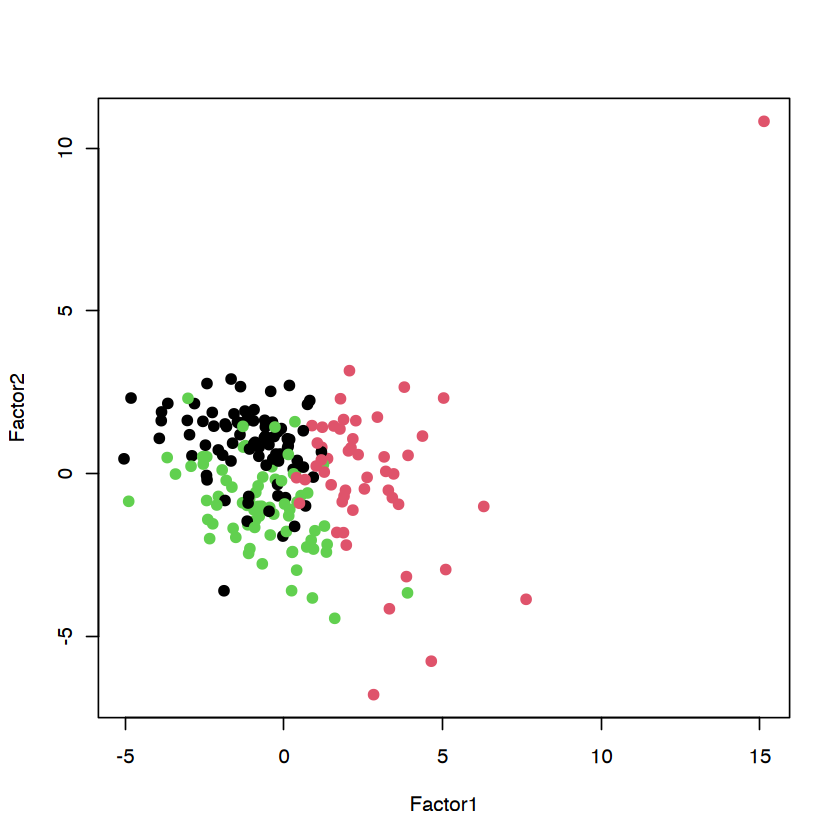

In [18]:
if (!requireNamespace("MOFA2", quietly = TRUE)) BiocManager::install("MOFA2")
library(MOFA2)

# MOFA2要求“行为特征、列为样本”
data_list_mofa <- list(
  cnv = cnv_mat_z,
  rna = rna_mat_z,
  pro = pro_mat_z
)

MOFAobject <- create_mofa(data_list_mofa)
MOFAobject <- prepare_mofa(MOFAobject)
MOFAobject <- run_mofa(MOFAobject, use_basilisk = FALSE)

# 查看潜在因子
factors <- get_factors(MOFAobject, factors = "all")$group1

# 用因子做聚类
set.seed(2024)
kmeans_res <- kmeans(factors, centers = 3)
mofa_clusters <- kmeans_res$cluster

# 可视化前2因子
plot(factors[,1], factors[,2], col = mofa_clusters, pch = 19, xlab = "Factor1", ylab = "Factor2")

In [21]:
# 假定subtypes, mofa_clusters变量的names是样本名（如"111"）
# 先转为data.frame
names(subtypes) <- common_samples
subtype_df <- data.frame(Sample=names(subtypes), iCluster=subtypes)
mofa_df <- data.frame(Sample=names(mofa_clusters), MOFA=mofa_clusters)

# 合并到sample_cluster，根据Sample列
sample_cluster2 <- sample_cluster %>%
  right_join(subtype_df, by="Sample") %>%
  right_join(mofa_df, by="Sample")

In [22]:
sample_cluster2$Ensemble <- as.factor(sample_cluster2$Ensemble)
sample_cluster2$iCluster <- as.factor(sample_cluster2$iCluster)
sample_cluster2$MOFA <- as.factor(sample_cluster2$MOFA)

In [23]:
dim(sample_cluster2)
head(sample_cluster2)

[1] 204  40

Sample,NMF,KMeans,Ensemble,Study,Platform,Sex,Age_num,Age_group,Country,...,"ALB, albumin, (g/L)",Preoperative AFP（ng/mL）,Preoperative CEA（ng/ml）,Preoperative CA19-9（U/ml）,"ALT, aminoleucine transferase (U/L)","γ-GT, γ-glutamyltransferase (U/L)",Genome sequencing,Protein profiling,iCluster,MOFA
<chr>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,...,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
115,1,3,C1,2022Dong,RNAseq (Illumina),Male,74,>60,China,...,39,42.7,2,8.1999999999999904,11,29,YES,YES,3,2
117,1,3,C1,2022Dong,RNAseq (Illumina),Female,64,>60,China,...,47,2.8,1,7.9,17,27,YES,YES,3,1
121,2,1,C2,2022Dong,RNAseq (Illumina),Female,71,>60,China,...,42,215.1,1.4,24.9,10,23,YES,YES,3,1
123,1,3,C1,2022Dong,RNAseq (Illumina),Male,55,40-60,China,...,44,2.1,0.8,30.4,89,384,YES,YES,2,3
125,3,2,C3,2022Dong,RNAseq (Illumina),Male,73,>60,China,...,34,2.4,7.2,196.3,23,45,YES,YES,2,3
133,3,2,C3,2022Dong,RNAseq (Illumina),Female,51,40-60,China,...,40,2,0.5,13.4,12,31,YES,YES,4,1


In [24]:
# 需要mclust包
if(!require(mclust)) install.packages("mclust")
library(mclust)

# 只用有完整标签的样本
df <- sample_cluster2 %>% filter(!is.na(iCluster), !is.na(MOFA), !is.na(Ensemble))

# ARI (Adjusted Rand Index) 比较
ari_ens_ic <- adjustedRandIndex(as.numeric(df$Ensemble), as.numeric(df$iCluster))
ari_ens_mofa <- adjustedRandIndex(as.numeric(df$Ensemble), as.numeric(df$MOFA))
ari_ic_mofa <- adjustedRandIndex(as.numeric(df$iCluster), as.numeric(df$MOFA))

cat("ARI(Ensemble, iClusterPlus):", ari_ens_ic, "\n")
cat("ARI(Ensemble, MOFA2):", ari_ens_mofa, "\n")
cat("ARI(iClusterPlus, MOFA2):", ari_ic_mofa, "\n")

# 列联表（混淆矩阵）
table(df$Ensemble, df$iCluster)
table(df$Ensemble, df$MOFA)
table(df$iCluster, df$MOFA)

Loading required package: mclust



Package 'mclust' version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.


Attaching package: 'mclust'


The following object is masked from 'package:purrr':

    map


The following object is masked from 'package:mgcv':

    mvn




ARI(Ensemble, iClusterPlus): 0.2708807 
ARI(Ensemble, MOFA2): 0.1898605 
ARI(iClusterPlus, MOFA2): 0.1651583 


       
         1  2  3  4
  C1     0 29  6  7
  C1_C2  0  1 10  0
  C1_C3  0  5  2  2
  C2     1  4 59 28
  C2_C3  0  1  0  1
  C3     0 10  0 38

       
         1  2  3
  C1    14 13 15
  C1_C2  5  4  2
  C1_C3  0  2  7
  C2    54 31  7
  C2_C3  0  0  2
  C3     8  1 39

   
     1  2  3
  1  0  1  0
  2  9 12 29
  3 39 35  3
  4 33  3 40


Attaching package: 'reshape2'


The following object is masked from 'package:tidyr':

    smiths




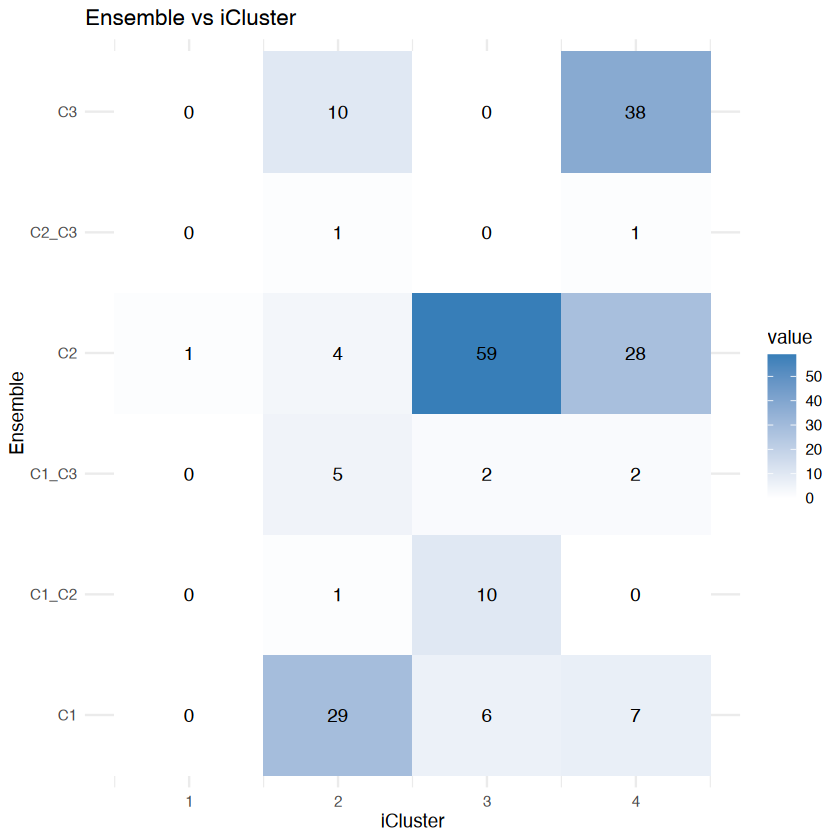

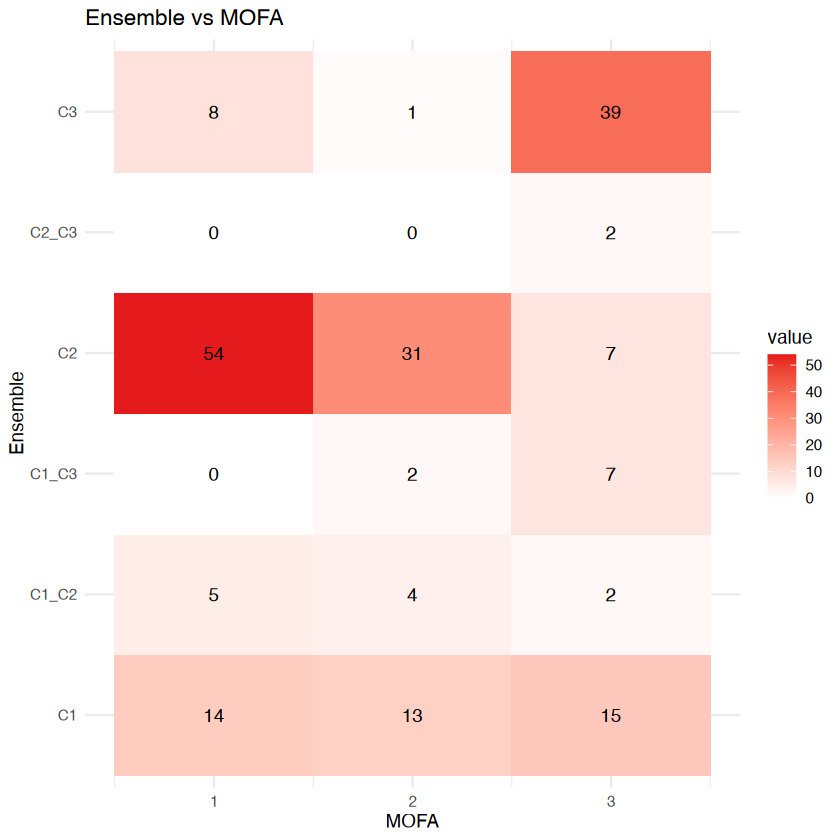

In [36]:
library(ggplot2)
library(reshape2)

# iCluster vs Ensemble
tab1 <- table(df$Ensemble, df$iCluster)
melt_tab1 <- melt(tab1)
ggplot(melt_tab1, aes(x=Var2, y=Var1, fill=value)) +
  geom_tile() + geom_text(aes(label=value), color="black") +
  scale_fill_gradient(low="white", high="#377eb8") +
  labs(x="iCluster", y="Ensemble", title="Ensemble vs iCluster") +
  theme_minimal()

# MOFA vs Ensemble
tab2 <- table(df$Ensemble, df$MOFA)
melt_tab2 <- melt(tab2)
ggplot(melt_tab2, aes(x=Var2, y=Var1, fill=value)) +
  geom_tile() + geom_text(aes(label=value), color="black") +
  scale_fill_gradient(low="white", high="#e41a1c") +
  labs(x="MOFA", y="Ensemble", title="Ensemble vs MOFA") +
  theme_minimal()

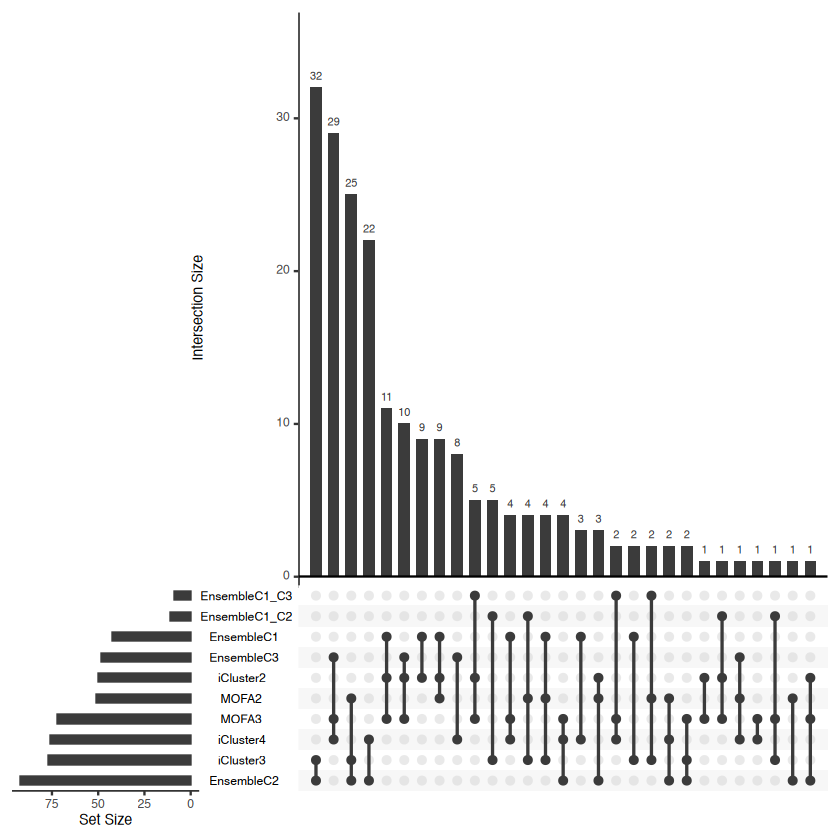

In [38]:
library(dplyr)
library(tidyr)
library(UpSetR)

# Step1: 选取分型列，转为factor
df_upset <- df %>%
  select(Sample, Ensemble, iCluster, MOFA) %>%
  mutate(across(c(Ensemble, iCluster, MOFA), as.factor))

# Step2: 为每个聚类类别生成0/1列（哑变量/one-hot编码）
df_bin <- model.matrix(~ Ensemble + iCluster + MOFA - 1, data = df_upset)
df_bin <- as.data.frame(df_bin)
df_bin$Sample <- df_upset$Sample

# Step3: UpSetR作图（去掉Sample列）
upset(df_bin[,-ncol(df_bin)], nsets = 10, order.by = "freq")

Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."


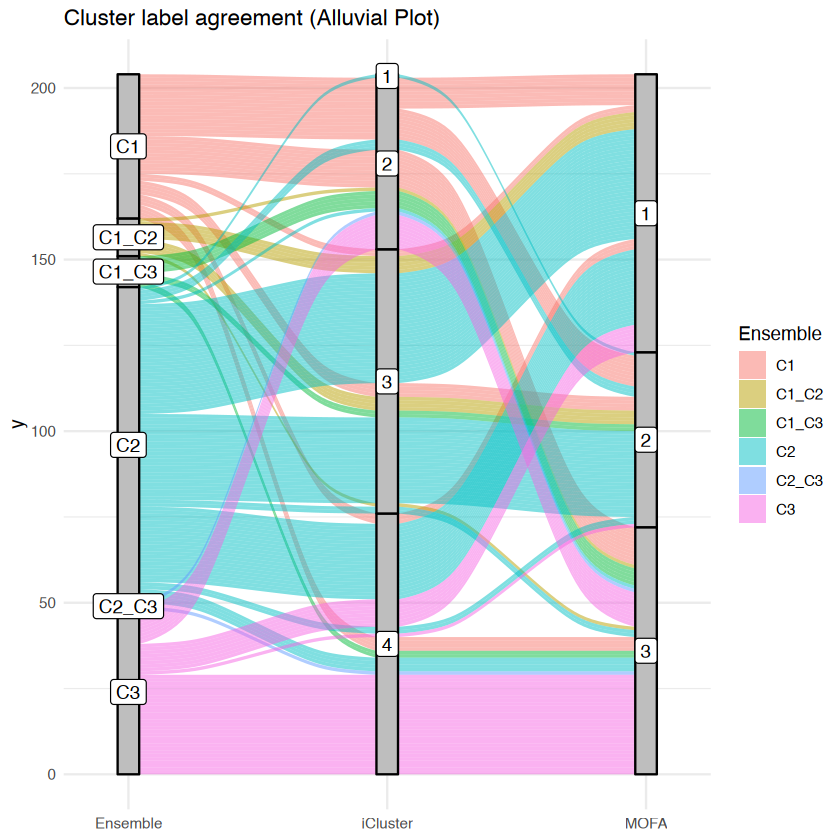

In [40]:
library(ggalluvial)
library(dplyr)

# 若有样本名
df_plot <- df %>% mutate(Sample = as.character(Sample))

ggplot(df_plot,
       aes(axis1=Ensemble, axis2=iCluster, axis3=MOFA, y=1)) +
  geom_alluvium(aes(fill=Ensemble), width = 1/12) +
  geom_stratum(width = 1/12, fill = "grey", color = "black") +
  geom_label(stat = "stratum", aes(label = after_stat(stratum))) +
  scale_x_discrete(limits = c("Ensemble", "iCluster", "MOFA"), expand = c(.1, .05)) +
  labs(title = "Cluster label agreement (Alluvial Plot)") +
  theme_minimal()

Welcome! Want to learn more? See two factoextra-related books at https://goo.gl/ve3WBa



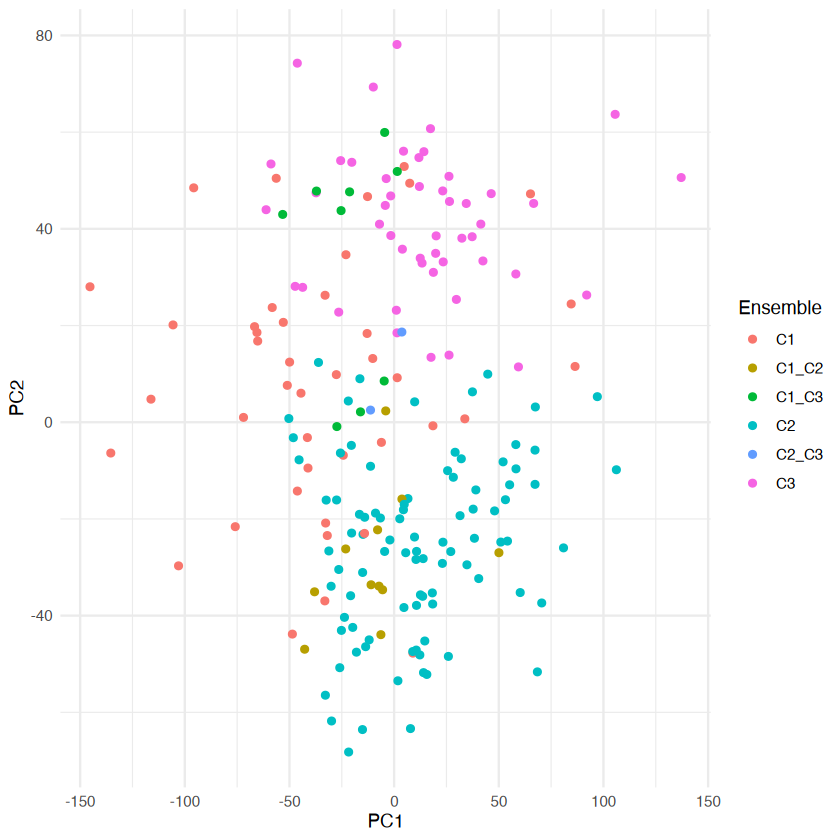

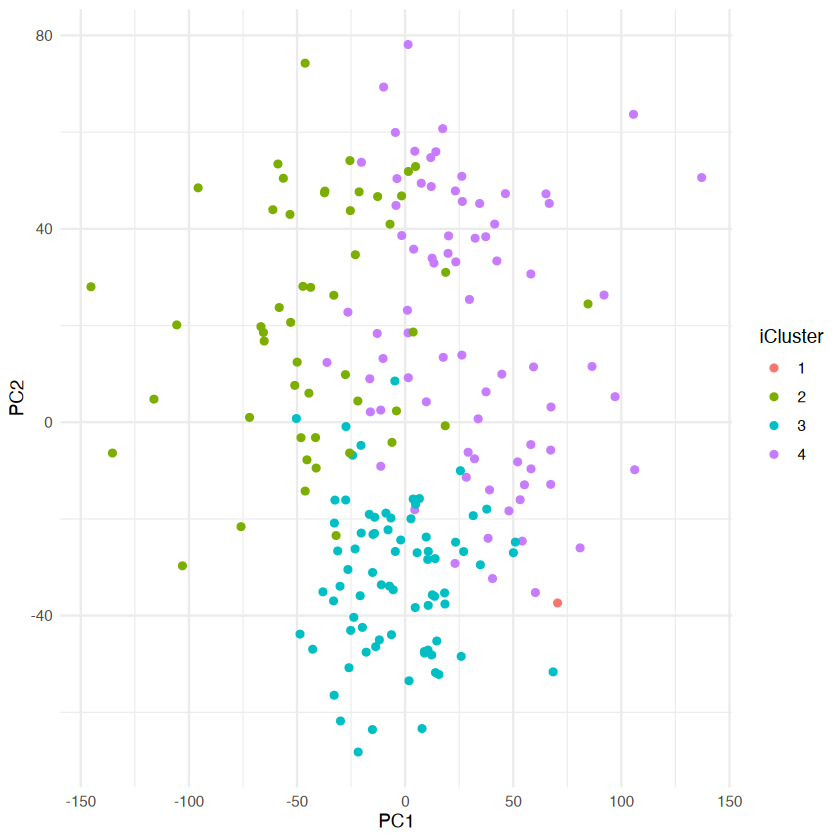

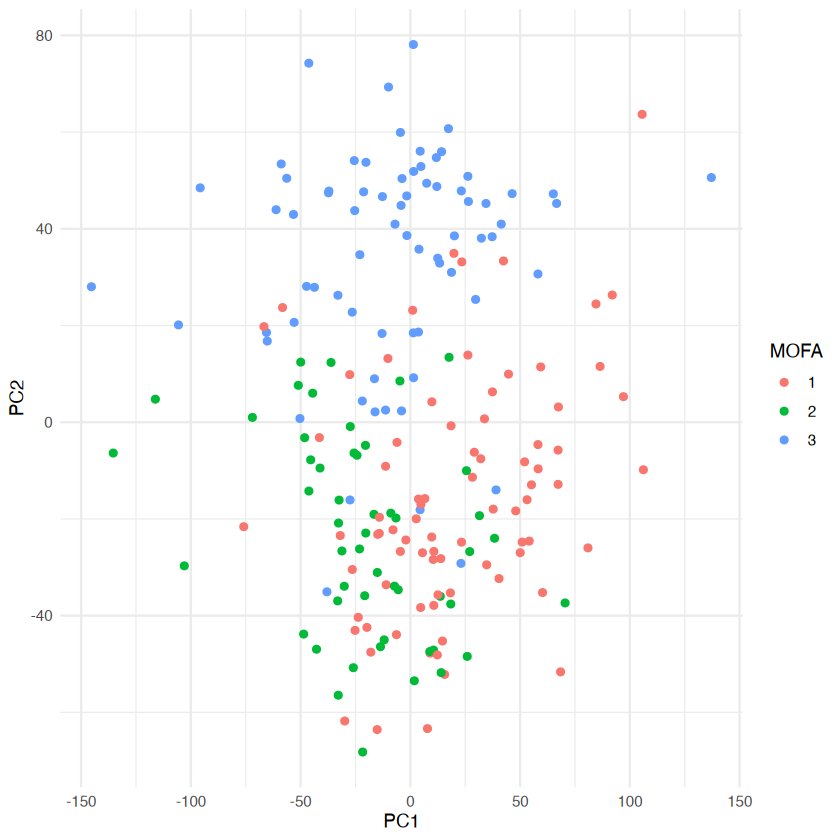

In [46]:
# 假设你有某个组学矩阵，比如 rna_mat_z （行为基因，列为样本，顺序与df一致）
library(FactoMineR)
library(factoextra)

# 取RNA表达为例
data4pca <- t(rna_mat_z[, df$Sample]) # 行为样本，列为基因

# 做PCA
pca_res <- prcomp(data4pca, scale. = TRUE)
df$PC1 <- pca_res$x[,1]
df$PC2 <- pca_res$x[,2]

# 再画
library(ggplot2)
ggplot(df, aes(x=PC1, y=PC2, color=Ensemble)) + geom_point() + theme_minimal()
ggplot(df, aes(x=PC1, y=PC2, color=iCluster)) + geom_point() + theme_minimal()
ggplot(df, aes(x=PC1, y=PC2, color=MOFA)) + geom_point() + theme_minimal()

In [32]:
write.csv(df, file="cluster_compare.csv", row.names = FALSE)

## **mRNA + Protein**

In [43]:
corrected_protein <- read.csv(file = "./0-Data/0-Data-corrected-protein.csv",row.names = 1)
# 处理列名：移除开头的X并将.替换为#
names(corrected_protein) <- gsub("^X", "", names(corrected_protein))  # 移除开头的X
names(corrected_protein) <- gsub("\\.", "#", names(corrected_protein))  # 将.替换为#

dim(corrected_protein)
head(corrected_protein)

[1] 8296  298

,115,117,121,123,125,133,135,137,141,145,...,CCA#80,CCA#82,CCA#85,CCA#89,CCA#90,CCA#91,CCA#93,CCA#94,CCA#95,CCA#98
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1-Mar,3.1384564,0.8706699,0.14056241,1.5345069,-0.7081415,0.1506957,-1.0347897,0.10437772,-0.7162476,0.1280358,...,-0.05748693,-0.3139260,-0.2721762,-0.3139260,-0.3139260,-0.31392597,-0.31392597,-0.0246579,-0.3139260,3.16264062
1-Sep,-0.2688108,-0.8639683,-0.02903576,0.0374228,-0.3743786,1.3348989,-0.6958552,0.07138807,-0.6512474,-0.2398088,...,-0.27107007,-0.3151318,0.1111752,0.2151971,-0.1134989,-0.31513180,-0.31513180,-0.1480897,1.9026639,-0.05396275
10-Sep,-0.3539828,1.0171749,0.87220542,-0.1167739,0.7928682,-0.4137493,-0.1039814,1.49972889,-0.4708291,0.8741091,...,-0.60604059,-0.1813856,-0.5568200,0.5497384,-0.3962590,0.06918692,-0.18104612,-0.5445431,0.8103248,-0.16599706
11-Sep,4.9194121,2.0747315,4.00125524,0.7944405,1.8756259,4.5729542,4.8903437,3.06515681,5.9058327,3.8977205,...,-0.42105606,7.9554454,0.2847590,2.2423199,6.3706208,1.93029716,4.05630668,3.1416764,4.9480262,1.83969055
15-Sep,0.6184967,6.3061826,1.71559410,5.0074285,2.9666833,1.2994895,2.2334499,1.53730941,3.4273133,3.2402421,...,17.70000414,6.7151872,5.8817229,5.0988536,-2.8957029,13.91257892,3.75136728,0.4321360,3.9726530,2.62787516
2-Mar,4.7671228,6.8301253,3.24270937,5.5093142,-0.2257457,0.8293558,-1.2262765,2.26071464,-0.9787906,2.5891553,...,6.58457094,-0.7454705,1.4576068,0.3295853,-0.4505965,1.20271948,-0.08359184,5.0910359,0.2063667,7.90645052


In [44]:
load(file =  "./1-Clustering/data/combined_expr_after_correction.rds")
dim(corrected_expr_limma)
head(corrected_expr_limma)

[1] 10531   586

,GSM2883928,GSM2883929,GSM2883930,GSM2883931,GSM2883932,GSM2883933,GSM2883934,GSM2883935,GSM2883936,GSM2883937,...,TCGA-ZH-A8Y4-01A,TCGA-W5-AA2Q-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA34-01A,TCGA-3X-AAVB-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA38-01A,TCGA-W5-AA2H-01A,TCGA-W5-AA2O-01A,TCGA-W5-AA2W-01A
TMSB10,10.82928,10.890999,11.94522,12.778273,10.995143,11.226208,10.035329,10.398659,11.30408,12.16933,...,10.99660,11.026177,11.094798,12.008558,11.481356,12.627119,11.769922,11.4156781,11.201563,9.495304
ALB,12.05004,13.178437,10.79637,5.770313,7.063872,4.553839,12.638745,12.447035,10.08065,10.02450,...,11.00465,12.196094,10.683190,12.497491,2.410946,8.453237,7.411365,0.4926482,12.583942,7.533481
FTL,10.66605,12.897749,11.72236,11.072817,12.143254,12.137395,13.854919,12.317509,11.09063,11.08043,...,11.76724,9.781075,10.558542,10.432385,12.301201,12.339945,13.363718,11.6431148,10.730668,11.445058
S100A6,10.31944,5.593509,11.54254,10.995845,11.064880,10.134493,7.784021,10.904630,10.58029,10.69710,...,10.62347,10.704640,8.700956,7.914385,12.343699,11.888619,10.589558,8.2747927,8.948155,8.407319
RPS18,10.09080,10.167330,10.44833,10.278913,9.563777,9.050844,9.202332,9.774162,11.49839,10.09671,...,10.64097,11.134008,9.614914,10.565745,9.542747,9.639386,9.873656,11.1388385,10.614570,9.653813
TMSB4X,10.61613,10.408689,11.31893,11.724414,11.308622,11.295856,10.777988,11.413705,10.88848,11.85332,...,10.43501,10.587907,10.379686,11.303271,11.737150,11.998210,10.570807,12.4690672,10.863712,9.242494


In [45]:
# 保证样本名一致，按交集排序
common_samples <- intersect(colnames(corrected_expr_limma), colnames(corrected_protein))
print(length(common_samples))
rna <- corrected_expr_limma[ , common_samples]
dim(rna)
head(rna)
protein <- corrected_protein[, common_samples]
dim(protein)
head(protein)

[1] 292


[1] 10531   292

,115,117,121,123,125,133,135,137,141,145,...,CCA#150,CCA#152,CCA#155,CCA#169,CCA#174,CCA#30,CCA#35,CCA#56,CCA#177,CCA#179
TMSB10,10.779386,11.209108,11.43570,9.970407,10.775964,11.648159,12.012757,12.471030,11.381120,11.209834,...,10.199406,10.686156,11.333350,11.287072,12.281046,10.792439,12.472811,11.630917,10.866204,11.744150
ALB,14.914644,13.822237,13.82560,13.385835,9.723532,6.118697,8.983563,11.489984,8.783284,7.662115,...,10.125256,12.166188,10.884071,12.021948,6.991834,12.119159,8.897496,8.240115,7.408854,3.991408
FTL,11.447903,10.823978,10.73736,12.072885,12.581201,12.176593,10.937886,10.999648,11.618346,10.181471,...,11.586513,11.364712,11.005691,12.834570,10.634527,11.220561,11.275456,10.966204,10.853328,11.128519
S100A6,7.436359,8.687726,10.39931,10.638920,10.030652,9.893170,10.895559,9.894928,9.860900,9.518410,...,10.428400,10.436201,8.627195,10.950056,12.350715,10.628523,11.488778,9.407364,10.583899,12.173708
RPS18,9.422476,9.146106,10.80067,9.676816,10.541761,10.097420,10.718990,10.109084,10.067697,9.897802,...,9.227733,9.395064,9.991834,9.739335,10.708327,9.815329,10.294798,10.251610,9.401234,10.438744
TMSB4X,8.573952,9.214621,11.55836,10.992200,10.281427,11.733197,10.992058,11.881176,11.230560,11.218492,...,9.068853,10.488856,11.146858,11.387786,11.858220,11.438235,12.138222,12.389582,12.546016,11.446958


[1] 8296  292

,115,117,121,123,125,133,135,137,141,145,...,CCA#150,CCA#152,CCA#155,CCA#169,CCA#174,CCA#30,CCA#35,CCA#56,CCA#177,CCA#179
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1-Mar,3.1384564,0.8706699,0.14056241,1.5345069,-0.7081415,0.1506957,-1.0347897,0.10437772,-0.7162476,0.1280358,...,0.37695296,0.0001571987,-0.2461660,-0.31392597,-0.2096112,-0.3139260,-0.01460532,-0.31392597,-0.3139260,-0.2414561
1-Sep,-0.2688108,-0.8639683,-0.02903576,0.0374228,-0.3743786,1.3348989,-0.6958552,0.07138807,-0.6512474,-0.2398088,...,-0.02685552,-0.3151317963,0.4478537,0.02552963,-0.3151318,-0.3151318,-0.20862365,0.17877696,-0.1869212,-0.3151318
10-Sep,-0.3539828,1.0171749,0.87220542,-0.1167739,0.7928682,-0.4137493,-0.1039814,1.49972889,-0.4708291,0.8741091,...,-0.27977021,-0.1676943217,0.7252919,1.95399668,0.5591865,1.2395058,1.50512738,1.28906589,-0.1759543,-0.2543678
11-Sep,4.9194121,2.0747315,4.00125524,0.7944405,1.8756259,4.5729542,4.8903437,3.06515681,5.9058327,3.8977205,...,-0.79651979,3.4176419406,7.5344329,4.52957754,5.7032631,8.4504270,4.32398073,4.55423388,3.5229223,1.1263476
15-Sep,0.6184967,6.3061826,1.71559410,5.0074285,2.9666833,1.2994895,2.2334499,1.53730941,3.4273133,3.2402421,...,-2.89570291,1.1659269670,1.3382427,3.48338678,8.6632597,7.7344015,5.67267966,0.36897344,3.5586835,-0.5581513
2-Mar,4.7671228,6.8301253,3.24270937,5.5093142,-0.2257457,0.8293558,-1.2262765,2.26071464,-0.9787906,2.5891553,...,-1.09126681,0.6889129440,3.5869519,-0.08983286,-1.0198542,1.5120086,-0.37172779,0.02559826,-1.2457457,-1.1785858


In [48]:
scale_rows <- function(mat) {
  t(scale(t(mat)))
}
rna_z <- scale_rows(rna)
protein_z <- scale_rows(protein)

In [49]:
set.seed(2024)
rna_sel <- sample(nrow(rna_z), min(500, nrow(rna_z)))
protein_sel <- sample(nrow(protein_z), min(500, nrow(protein_z)))

rna_sub <- rna_z[rna_sel, ]
protein_sub <- protein_z[protein_sel, ]

In [50]:
if (!requireNamespace("iClusterPlus", quietly = TRUE)) BiocManager::install("iClusterPlus")
library(iClusterPlus)

# 转置为样本为行、特征为列
rna_sub_t <- t(rna_sub)
protein_sub_t <- t(protein_sub)

# 开始聚类（K=2~5都可尝试，这里以K=3为例）
fit <- iClusterPlus(
  dt1 = rna_sub_t,
  dt2 = protein_sub_t,
  type = c("gaussian", "gaussian"),
  K = 3
)

subtypes <- fit$clusters
names(subtypes) <- colnames(rna_sub)  # 样本名赋值，rna_sub/protein_sub列名即样本名
table(subtypes)

subtypes
  1   2   3   4 
  2  60 130 100 

In [51]:
if (!requireNamespace("MOFA2", quietly = TRUE)) BiocManager::install("MOFA2")
library(MOFA2)

# MOFA2要求行为特征、列为样本
data_list <- list(
  RNA = rna_sub,
  Protein = protein_sub
)

MOFAobject <- create_mofa(data_list)
MOFAobject <- prepare_mofa(MOFAobject)
MOFAobject <- run_mofa(MOFAobject)

factors <- get_factors(MOFAobject, factors = "all")$group1  # 样本 x 因子

# 用前2因子做K-means聚类
set.seed(2024)
mofa_clusters <- kmeans(factors, centers = 3)$cluster
names(mofa_clusters) <- colnames(rna_sub)
table(mofa_clusters)

Creating MOFA object from a list of matrices (features as rows, sample as columns)...


Warning message in .rename_duplicated_features(object):
"There are duplicated features names across different views. We will add the suffix *_view* only for those features 
            Example: if you have both TP53 in mRNA and mutation data it will be renamed to TP53_mRNA, TP53_mutation"


Checking data options...

No data options specified, using default...

No training options specified, using default...

No model options specified, using default...

Warning message in run_mofa(MOFAobject):
"No output filename provided. Using /var/folders/5f/48rk2mh94f56vlbr6lpsdxjw0000gn/T//RtmpAbD512/mofa_20250727-152118.hdf5 to store the trained model.

"
Connecting to the mofapy2 python package using reticulate (use_basilisk = FALSE)... 
    Please make sure to manually specify the right python binary when loading R with reticulate::use_python(..., force=TRUE) or the right conda environment with reticulate::use_condaenv(..., force=TRUE)
    If you prefer to let us automatically install a conda environment with 'mofapy2' installed using the 'basilisk' package, please use the argument 'use_basilisk = TRUE'


Warning message in run_mofa(MOFAobject):
"The latest mofapy2 version is 0.7.0, you are using 0.7.2. Please upgrade with 'pip install mofapy2'"
Warning message in .quality_control

mofa_clusters
  1   2   3 
155  52  85 

In [52]:
# 假定subtypes, mofa_clusters变量的names是样本名（如"111"）
# 先转为data.frame
names(subtypes) <- common_samples
subtype_df <- data.frame(Sample=names(subtypes), iCluster=subtypes)
mofa_df <- data.frame(Sample=names(mofa_clusters), MOFA=mofa_clusters)

# 合并到sample_cluster，根据Sample列
sample_cluster2 <- sample_cluster %>%
  right_join(subtype_df, by="Sample") %>%
  right_join(mofa_df, by="Sample")

In [53]:
sample_cluster2$Ensemble <- as.factor(sample_cluster2$Ensemble)
sample_cluster2$iCluster <- as.factor(sample_cluster2$iCluster)
sample_cluster2$MOFA <- as.factor(sample_cluster2$MOFA)

In [54]:
# 需要mclust包
if(!require(mclust)) install.packages("mclust")
library(mclust)

# 只用有完整标签的样本
df <- sample_cluster2 %>% filter(!is.na(iCluster), !is.na(MOFA), !is.na(Ensemble))

# ARI (Adjusted Rand Index) 比较
ari_ens_ic <- adjustedRandIndex(as.numeric(df$Ensemble), as.numeric(df$iCluster))
ari_ens_mofa <- adjustedRandIndex(as.numeric(df$Ensemble), as.numeric(df$MOFA))
ari_ic_mofa <- adjustedRandIndex(as.numeric(df$iCluster), as.numeric(df$MOFA))

cat("ARI(Ensemble, iClusterPlus):", ari_ens_ic, "\n")
cat("ARI(Ensemble, MOFA2):", ari_ens_mofa, "\n")
cat("ARI(iClusterPlus, MOFA2):", ari_ic_mofa, "\n")

# 列联表（混淆矩阵）
table(df$Ensemble, df$iCluster)
table(df$Ensemble, df$MOFA)
table(df$iCluster, df$MOFA)

ARI(Ensemble, iClusterPlus): 0.3727836 
ARI(Ensemble, MOFA2): 0.4249516 
ARI(iClusterPlus, MOFA2): 0.578584 


       
          1   2   3   4
  C1      0  32   8  11
  C1_C2   0   4  19   0
  C1_C3   0   5   3  11
  C2      1   8 100  17
  C2_C3   0   1   0   1
  C3      1  10   0  60

       
          1   2   3
  C1     12  25  14
  C1_C2  19   3   1
  C1_C3   2   3  14
  C2    116   7   3
  C2_C3   1   1   0
  C3      5  13  53

   
      1   2   3
  1   0   1   1
  2   4  45  11
  3 127   0   3
  4  24   6  70

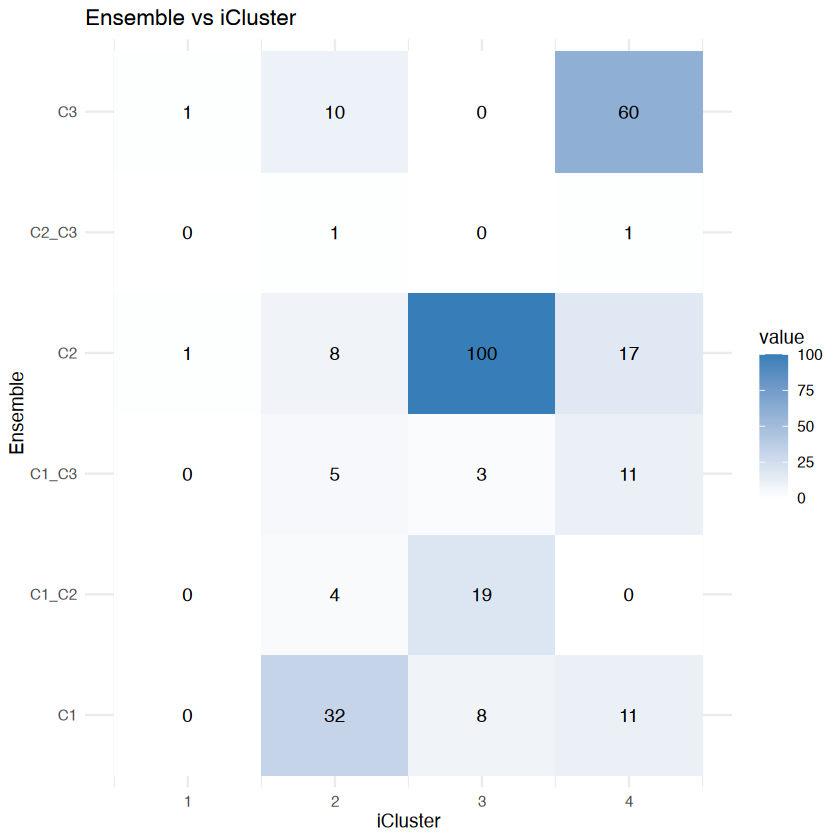

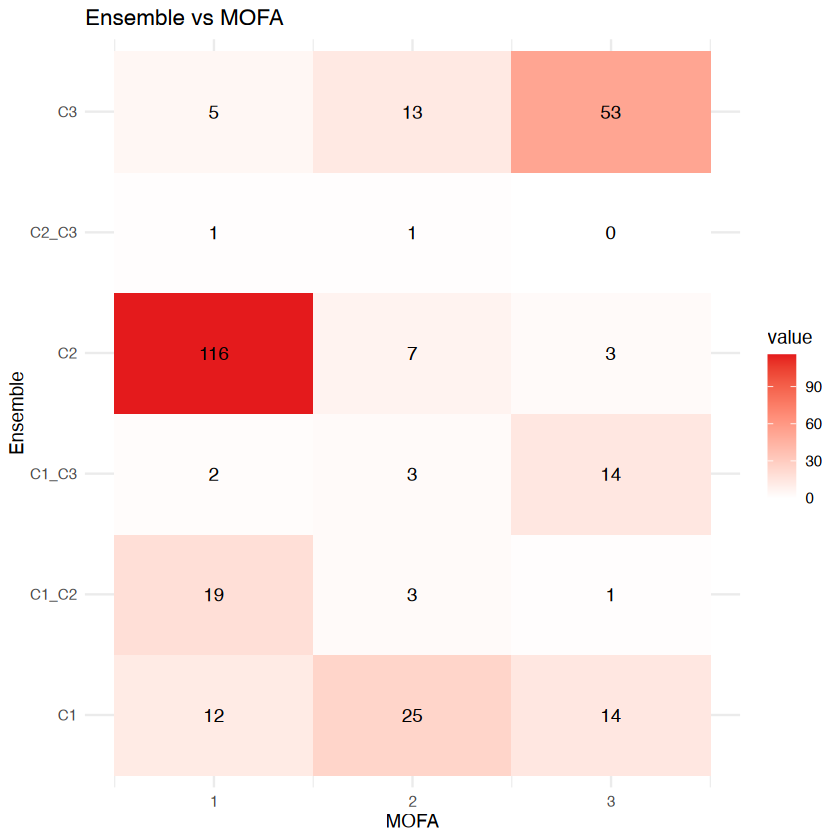

In [55]:
library(ggplot2)
library(reshape2)

# iCluster vs Ensemble
tab1 <- table(df$Ensemble, df$iCluster)
melt_tab1 <- melt(tab1)
ggplot(melt_tab1, aes(x=Var2, y=Var1, fill=value)) +
  geom_tile() + geom_text(aes(label=value), color="black") +
  scale_fill_gradient(low="white", high="#377eb8") +
  labs(x="iCluster", y="Ensemble", title="Ensemble vs iCluster") +
  theme_minimal()

# MOFA vs Ensemble
tab2 <- table(df$Ensemble, df$MOFA)
melt_tab2 <- melt(tab2)
ggplot(melt_tab2, aes(x=Var2, y=Var1, fill=value)) +
  geom_tile() + geom_text(aes(label=value), color="black") +
  scale_fill_gradient(low="white", high="#e41a1c") +
  labs(x="MOFA", y="Ensemble", title="Ensemble vs MOFA") +
  theme_minimal()

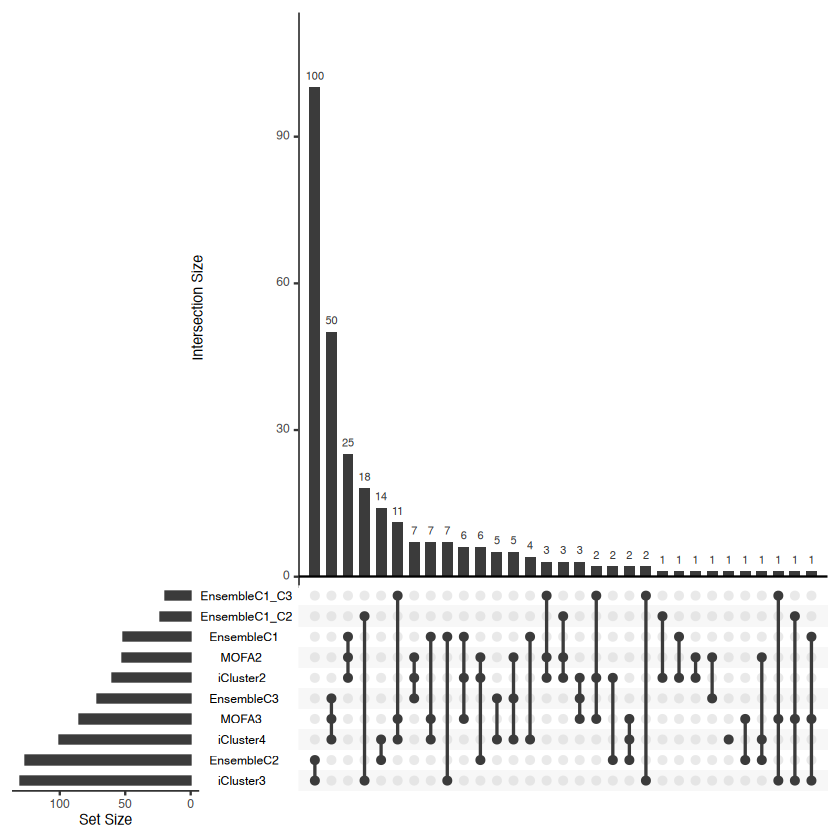

In [56]:
library(dplyr)
library(tidyr)
library(UpSetR)

# Step1: 选取分型列，转为factor
df_upset <- df %>%
  select(Sample, Ensemble, iCluster, MOFA) %>%
  mutate(across(c(Ensemble, iCluster, MOFA), as.factor))

# Step2: 为每个聚类类别生成0/1列（哑变量/one-hot编码）
df_bin <- model.matrix(~ Ensemble + iCluster + MOFA - 1, data = df_upset)
df_bin <- as.data.frame(df_bin)
df_bin$Sample <- df_upset$Sample

# Step3: UpSetR作图（去掉Sample列）
upset(df_bin[,-ncol(df_bin)], nsets = 10, order.by = "freq")

Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."
Warning message in to_lodes_form(data = data, axes = axis_ind, discern = params$discern):
"Some strata appear at multiple axes."


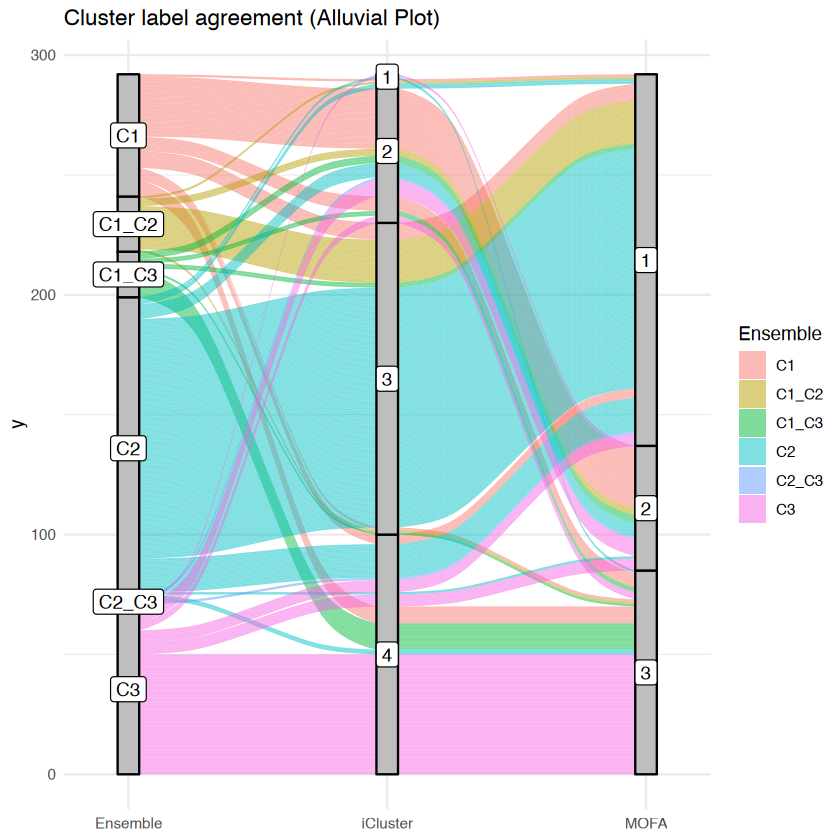

In [57]:
library(ggalluvial)
library(dplyr)

# 若有样本名
df_plot <- df %>% mutate(Sample = as.character(Sample))

ggplot(df_plot,
       aes(axis1=Ensemble, axis2=iCluster, axis3=MOFA, y=1)) +
  geom_alluvium(aes(fill=Ensemble), width = 1/12) +
  geom_stratum(width = 1/12, fill = "grey", color = "black") +
  geom_label(stat = "stratum", aes(label = after_stat(stratum))) +
  scale_x_discrete(limits = c("Ensemble", "iCluster", "MOFA"), expand = c(.1, .05)) +
  labs(title = "Cluster label agreement (Alluvial Plot)") +
  theme_minimal()

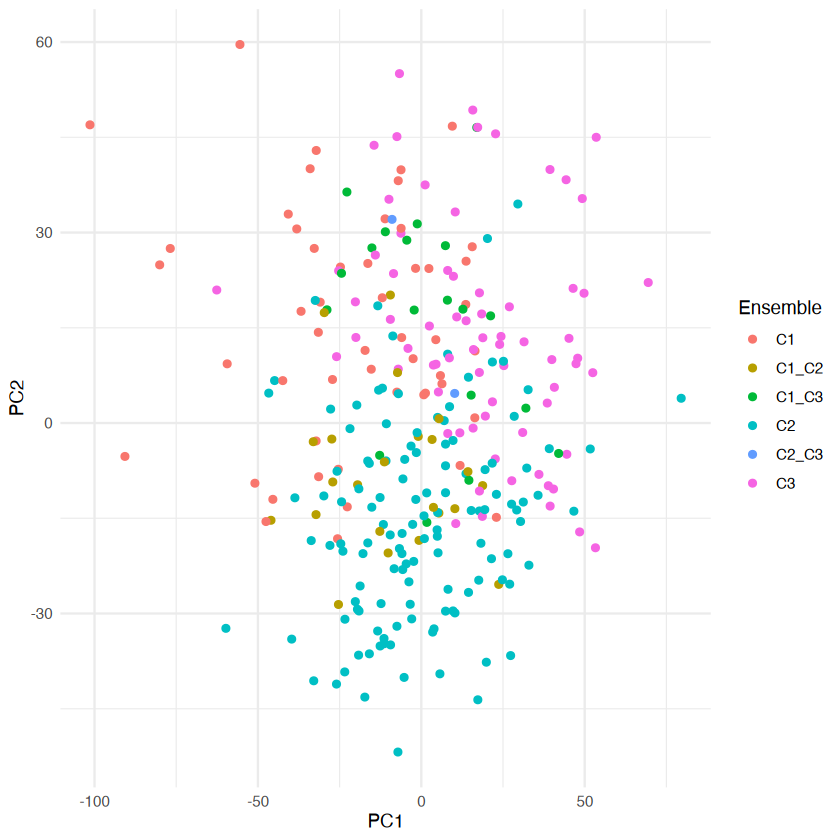

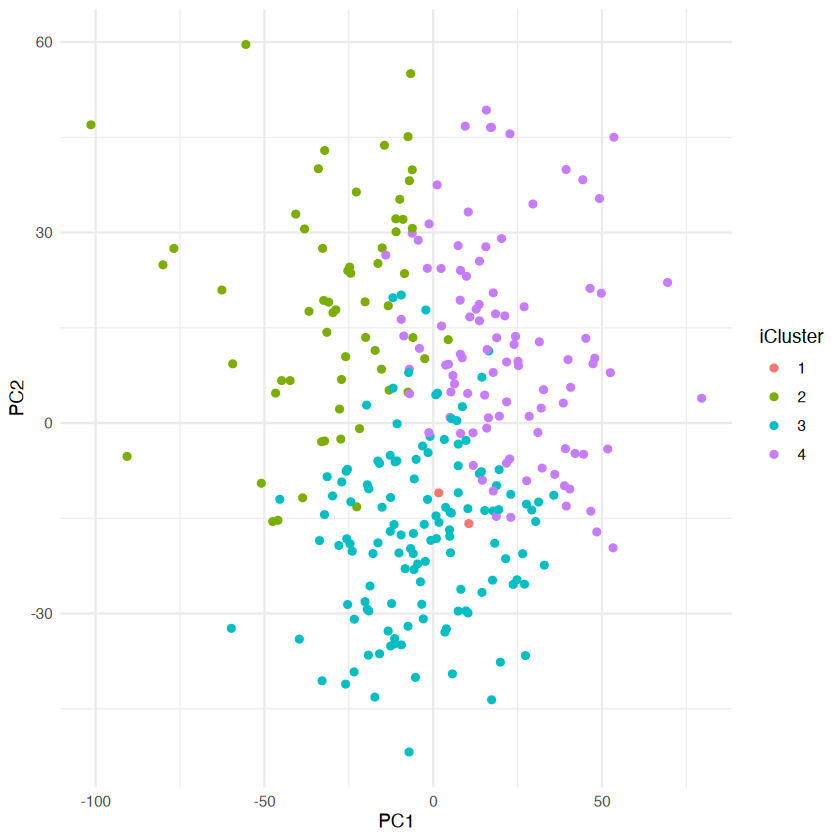

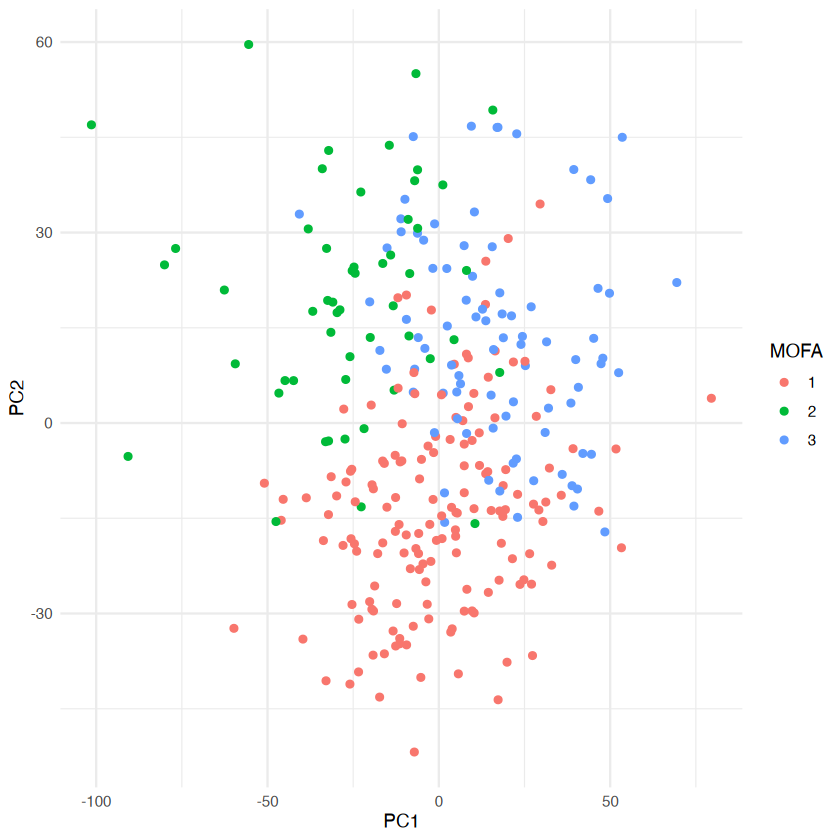

In [63]:
# 假设你有某个组学矩阵，比如 rna_mat_z （行为基因，列为样本，顺序与df一致）
library(FactoMineR)
library(factoextra)

# 取RNA表达为例
data4pca <- t(protein_z[, df$Sample]) # 行为样本，列为基因

# 做PCA
pca_res <- prcomp(data4pca, scale. = TRUE)
df$PC1 <- pca_res$x[,1]
df$PC2 <- pca_res$x[,2]

# 再画
library(ggplot2)
ggplot(df, aes(x=PC1, y=PC2, color=Ensemble)) + geom_point() + theme_minimal()
ggplot(df, aes(x=PC1, y=PC2, color=iCluster)) + geom_point() + theme_minimal()
ggplot(df, aes(x=PC1, y=PC2, color=MOFA)) + geom_point() + theme_minimal()